<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/Funcao_de_Ativacao_Do_Neuronio_a_Rede.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/Funcao_de_Ativacao_Do_Neuronio_a_Rede.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# O que a função de ativação realmente faz?
### Do neurônio humano à rede neural em NumPy — a mesma rede, quatro ativações

**Euripedes Gomes PhD**

Este notebook reconstrói, passo a passo, o experimento do post de @neuron.machinelearning: uma rede pequena (2-16-16-1), os mesmos dados, os mesmos pesos iniciais e os mesmos 600 passos de treino. Só a função de ativação *f* muda — e o resultado vai de 35,6% a 96,4% de acerto.

Cada fase segue o mesmo método: **1) Introdução · 2) Código · 3) Saída · 4) Observação**.

| Fase | Conteúdo | Situação |
|---|---|---|
| 0 | A rede pronta, em execução camada por camada (animação) | neste notebook |
| 1 | Do neurônio humano ao neurônio artificial | neste notebook |
| 2 | Os dados e a rede (dois anéis, rede 2-16-16-1) | neste notebook |
| 3 | Backprop à mão e o treino das quatro redes | neste notebook |
| 4 | Resultados: fronteiras, acurácia e qual ativação usar | neste notebook |

---
# Fase 0 — A rede pronta, em execução

## 0.1 Introdução

Antes de construir qualquer coisa, vale ver o ponto de chegada: a rede que este notebook monta, **já treinada e funcionando**.

A figura abaixo é uma animação, no mesmo espírito da Figura 19 da CNN (a rede convolucional em execução), adaptada para a nossa rede 2-16-16-1. Ela mostra um único ponto entrando na rede, passando pelas duas camadas ocultas e saindo como uma probabilidade.

| Coluna | O que mostra |
|---|---|
| Os dados | O mapa dos dois anéis. O fundo colorido é o que a rede prevê em cada região |
| Camada 0, Entrada | As duas coordenadas do ponto escolhido, $x_1$ e $x_2$ |
| Camada 1, Oculta 1 | 16 neurônios: soma ponderada das 2 entradas + bias, depois a ativação $f$ |
| Camada 2, Oculta 2 | 16 neurônios: soma ponderada dos 16 valores anteriores + bias, depois $f$ |
| Camada 3, Saída | 1 neurônio com sigmoid: a probabilidade de o ponto ser da classe 1 |

Uma diferença importante em relação à animação da CNN: lá os filtros eram fixos e o resultado, ilustrativo. **Aqui a rede é real.** Os pesos são os que o treino da Fase 3 produz, e a conta feita na tela é a mesma que vamos programar na Fase 2.

O que dá para fazer na figura:

- **Trocar a ativação** e ver a mesma rede, com o mesmo ponto, chegar a respostas diferentes.
- **Clicar no mapa** para escolher qualquer ponto do plano, ou **sortear** um ponto de teste (nesse caso a figura diz se a rede acertou).
- **Passar o mouse sobre um neurônio** para ler a soma $z$ e o valor $f(z)$ dele.

Não é preciso entender tudo agora. Neurônio, peso, bias, ativação e treino são explicados, um por vez, nas Fases 1 a 4. Vale voltar a esta figura depois de cada fase.

## 0.2 Código

São duas células.

**A primeira é Python** e é curta: `mostrar_rede` exibe a página dentro do notebook e `salvar_rede` grava a mesma página em arquivo.

- O `iframe` é uma "janela" dentro da saída da célula, onde a página roda isolada do resto do notebook.
- `html.escape` troca os caracteres especiais da página (aspas, `<`, `>`) para que ela caiba dentro do `iframe` sem quebrar.

In [ ]:
import html                                  # prepara o texto da página para ir dentro do notebook
from IPython.display import HTML, display    # mostra uma página HTML na saída da célula


def mostrar_rede(altura=800):
    """Mostra a rede animada dentro do notebook."""
    quadro = f'<div><iframe srcdoc="{html.escape(PAGINA_REDE)}" width="100%" height="{altura}" style="border:0"></iframe></div>'
    display(HTML(quadro))


def salvar_rede(nome_do_arquivo="MLP_em_execucao_by_Euripedes_Gomes.html"):
    """Grava a mesma animação como arquivo HTML independente (abre em qualquer navegador)."""
    with open(nome_do_arquivo, "w", encoding="utf-8") as arquivo:
        arquivo.write(PAGINA_REDE)
    print("Arquivo salvo:", nome_do_arquivo)

**A segunda célula é a página da animação**, escrita em HTML, CSS e JavaScript, não em Python. Ela desenha os círculos e as linhas, faz a animação e já carrega, na linha `const D=...`, os pesos das quatro redes treinadas e 300 pontos de teste. Não é preciso entendê-la linha a linha: basta saber que ela refaz no navegador a conta da rede. No Colab ela aparece recolhida, só com o título; um duplo clique no título abre o código.

In [ ]:
#@title Página da animação (HTML + JavaScript) — clique duas vezes aqui para ver o código
PAGINA_REDE = r"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>MLP Camada a Camada</title>
<style>
:root{--ink:#13233f;--blue:#1f5fa8;--gold:#e8a317;--line:#d3d9e4;--ok:#2e9e5b;--mute:#667391;
  --sans:"IBM Plex Sans",system-ui,-apple-system,"Segoe UI",sans-serif;--mono:"IBM Plex Mono",ui-monospace,Menlo,Consolas,monospace;color-scheme:light}
*{box-sizing:border-box}
html,body{margin:0;background:#fff;color:var(--ink);font-family:var(--sans)}
#controls{display:flex;flex-wrap:wrap;gap:10px;align-items:center;padding:8px 14px;font-size:13px;border-bottom:1px solid var(--line)}
#controls button,#controls select{font:inherit;height:30px;border-radius:6px;border:1px solid var(--blue);background:#fff;color:var(--blue);padding:0 12px;cursor:pointer}
#controls button:hover,#controls select:hover{background:#eef4fb}
#controls button.primary{background:var(--blue);color:#fff;font-weight:600}
#controls label{display:flex;align-items:center;gap:6px;color:var(--mute)}
#controls input[type=checkbox]{accent-color:var(--blue);width:15px;height:15px}
#controls .sep{width:1px;height:20px;background:var(--line)}
button:focus-visible,select:focus-visible,input:focus-visible{outline:3px solid var(--gold);outline-offset:2px}
svg{display:block;width:100%;height:auto;max-height:calc(100vh - 50px);margin:0 auto;font-family:var(--sans)}
.t-title{font-size:21px;font-weight:700;fill:var(--ink)}
.t-sub{font-size:12px;fill:var(--mute)}
.t-author{font-size:15px;font-weight:700;fill:#b73779}
.t-chip{font:600 10px var(--mono);letter-spacing:.08em;fill:var(--mute)}
.t-chip.active{fill:var(--gold)} .t-chip.done{fill:var(--blue)}
.t-name{font-size:15px;font-weight:700;fill:var(--ink)}
.t-small{font-size:11px;fill:var(--mute)}
.t-lab{font-size:12px;font-weight:700;fill:var(--ink)}
.t-cap{font-size:10.5px;font-style:italic;fill:var(--mute)}
.t-val{font:600 12px var(--mono);fill:var(--ink)}
.t-msg{font-size:12.5px;fill:var(--ink)}
.band{fill:rgba(232,163,23,.10);stroke:rgba(232,163,23,.8);stroke-width:1.5;stroke-dasharray:6 4;opacity:0}
.band.on{opacity:1;animation:bandblink .55s ease-in-out infinite alternate}
@keyframes bandblink{from{fill:rgba(232,163,23,.05)}to{fill:rgba(232,163,23,.22)}}
.node{fill:#fff;stroke:#c3cad8;stroke-width:2}
.node.done{stroke:var(--blue)}
.node.busy{animation:blink .45s ease-in-out infinite alternate}
@keyframes blink{from{stroke:var(--gold);stroke-width:2}to{stroke:#ffd166;stroke-width:4.5}}
.onode.done{stroke:var(--ok);stroke-width:3.5}
.wire{stroke:var(--line);fill:none}
.wire.flow{stroke:var(--gold)!important;stroke-opacity:1!important;stroke-dasharray:6 5;animation:dash .5s linear infinite}
@keyframes dash{to{stroke-dashoffset:-11}}
.pill rect{fill:#e7ebf2} .pill text{font:600 11px var(--mono);fill:var(--mute)}
.pill.active rect{fill:var(--gold)} .pill.active text{fill:#3b2a00}
.pill.done rect{fill:var(--blue)} .pill.done text{fill:#fff}
#resbox{fill:#fff;stroke:#c3cad8;stroke-width:1.5}
#resbox.on{fill:#f1faf5;stroke:var(--ok)}
#mapa{cursor:crosshair}
.dim{opacity:.4}
@media (prefers-reduced-motion:reduce){.band.on,.node.busy,.wire.flow{animation:none}.node.busy{stroke:var(--gold);stroke-width:4}}
@media print{#controls{display:none}}
</style>
</head>
<body>
<div id="controls">
  <label for="selAtiv">Ativação
    <select id="selAtiv"></select>
  </label>
  <button type="button" id="btnSorteio">Sortear ponto de teste</button>
  <span class="sep"></span>
  <label for="selVel">Velocidade
    <select id="selVel">
      <option value="1.8">lenta</option>
      <option value="1" selected>normal</option>
      <option value="0.5">rápida</option>
    </select>
  </label>
  <label for="chkLoop"><input type="checkbox" id="chkLoop">Repetir</label>
  <button type="button" class="primary" id="btnRun">&#9654; Executar de novo</button>
</div>
<svg id="palco" viewBox="0 0 1123 718" role="img" aria-label="Rede neural 2-16-16-1 em execução, camada por camada"></svg>

<script>
(function(){
"use strict";
const D={"redes":{"sem ativação":{"W":[[[0.06425,-0.06749,0.40864,0.0411,-0.34391,0.19088,0.89581,0.63913,-0.52037,-0.81172,-0.37366,0.11042,-1.46618,-0.22279,-0.76513,-0.44973],[-0.40777,-0.20125,0.24517,0.71497,-0.06755,0.92266,-0.48066,0.23967,0.62564,0.12799,-0.47757,-0.60281,-0.21204,0.11208,-0.64615,-0.10346]],[[-0.03835,0.13091,0.05223,0.07837,-0.15655,-0.02371,0.19959,0.38174,-0.31679,0.37704,0.34024,0.1946,0.07889,-0.07057,0.36896,0.48337],[0.45703,0.31818,0.09611,-0.30302,0.00153,0.16877,-0.31075,0.10404,0.1072,0.16989,-0.28272,-0.17232,-0.10349,-0.28837,0.43565,-0.10326],[0.06445,-0.03592,0.37821,0.33379,0.15061,-0.56452,-0.01755,0.15585,0.25202,-0.14326,0.41989,-0.31183,-0.18199,0.22194,0.00949,0.44644],[0.03519,-0.1371,-0.10349,-0.26012,-0.33096,0.14105,0.12367,0.30645,-0.18608,0.43027,-0.09677,0.40521,-0.13064,-0.19871,0.05642,0.23249],[0.04866,-0.16211,-0.33025,-0.36321,0.13609,0.26231,-0.02547,-0.2536,0.21559,-0.32603,-0.16067,0.14757,-0.5421,0.10978,-0.1394,0.04062],[-0.03734,0.0836,0.16014,-0.16814,0.33631,0.15445,0.17739,0.26331,0.20127,0.22348,-0.0196,-0.33901,-0.07061,-0.2166,-0.36582,0.0277],[-0.15044,-0.23864,-0.26055,0.0963,0.06944,0.30294,-0.02056,0.23375,0.35661,0.29446,-0.6095,0.31309,0.04566,0.08149,0.07971,0.10126],[0.06766,-0.06353,-0.47755,0.00891,-0.22676,0.23513,-0.09665,-0.01331,-0.20507,-0.11808,-0.02962,-0.36171,0.02564,-0.05767,-0.31255,-0.59936],[0.12918,-0.07707,-0.13365,-0.06495,0.45782,-0.00692,0.02376,-0.36673,0.41048,0.22832,0.26853,0.01176,0.23687,0.09738,0.15606,-0.04205],[-0.35058,0.2251,-0.47099,-0.08017,-0.03336,-0.23431,0.18571,-0.02317,-0.11356,0.1177,-0.08233,0.33038,0.12338,-0.09536,-0.47623,-0.2909],[0.28835,-0.04227,-0.05837,0.39298,-0.30457,-0.12293,-0.08804,0.17079,-0.16961,-0.16459,-0.3668,0.16635,0.23323,-0.09823,0.04943,-0.28827],[-0.11099,0.33154,0.03844,0.56685,-0.18791,0.157,-0.03589,0.15374,-0.00387,-0.14506,-0.20191,0.75987,-0.00265,-0.49328,-0.15732,0.1808],[-0.09158,0.276,0.26826,-0.0974,-0.07154,-0.18575,-0.11212,-0.30281,0.28884,0.37366,-0.24349,-0.32525,-0.35148,-0.18284,-0.7492,-0.24196],[0.32518,-0.08888,0.21306,-0.12695,0.44323,0.05424,-0.09342,0.64223,-0.08216,-0.30625,0.05247,-0.01014,0.27279,-0.22662,0.20334,0.21085],[-0.14355,-0.00473,-0.19627,0.54107,-0.14101,-0.06483,-0.22203,-0.0381,-0.0107,0.17503,-0.10275,-0.06715,-0.28653,-0.1636,0.70962,0.28676],[-0.18374,-0.35606,-0.23687,-0.02313,0.02308,-0.1656,-0.30009,0.37626,0.10925,-0.10181,-0.03082,-0.14302,-0.70585,0.04711,-0.25937,-0.23225]],[[-0.11203],[0.12515],[-0.16009],[-0.24079],[0.13127],[0.10482],[-0.15489],[0.11147],[-0.04307],[0.05626],[-0.16979],[0.12868],[0.2031],[0.12279],[0.11514],[-0.60275]]],"b":[[-0.01673,0.01228,-0.03779,-0.00078,0.00116,-0.00064,0.01461,0.026,0.00502,0.01678,0.00819,-0.01112,-0.00991,0.00152,-0.02012,7e-05],[-0.00527,0.00525,-0.0108,-0.01608,0.00791,0.00925,-0.00742,0.0075,-0.00315,0.00232,-0.00996,0.00709,0.01454,0.00807,0.0062,-0.03565],[0.04023]]},"sigmoid":{"W":[[[0.41277,-0.33669,1.07056,0.15006,-0.72079,0.28609,1.04472,0.77031,-0.59944,-1.24154,-0.53252,0.07264,-1.70886,0.00796,-1.14692,-0.95669],[-0.52337,-0.22006,0.39117,0.82259,-0.14614,1.0266,-0.44406,0.39457,0.81267,0.01599,-0.68571,-0.98247,-0.36971,0.2897,-1.13606,-0.3155]],[[-0.03789,0.13462,0.04662,0.41087,-0.21658,-0.02952,0.20856,0.37208,-0.30313,0.4029,0.3643,0.173,0.04251,-0.0987,0.3568,0.72036],[0.44798,0.34276,0.07762,-0.15141,-0.01774,0.1803,-0.31641,0.1287,0.118,0.19778,-0.28053,-0.16256,-0.28954,-0.32014,0.43049,-0.16216],[0.08773,-0.16852,0.47681,0.44114,0.00337,-0.65241,0.01849,0.08844,0.22706,-0.19979,0.48226,-0.47426,0.14888,0.23168,-0.02638,1.12631],[0.04372,-0.22148,-0.0412,-0.49974,-0.39469,0.09574,0.13545,0.29578,-0.21012,0.38547,-0.07782,0.31536,0.0879,-0.16583,0.0351,0.46203],[0.03421,-0.12588,-0.34665,-0.26308,0.12638,0.27035,-0.03873,-0.21388,0.22799,-0.29677,-0.16592,0.16807,-0.8854,0.05089,-0.14798,-0.16459],[-0.02282,-0.00706,0.21754,-0.48263,0.28802,0.12506,0.19684,0.25692,0.1757,0.17598,0.0023,-0.42525,0.27405,-0.14688,-0.38113,0.27631],[-0.13739,-0.24332,-0.29573,0.28753,0.04933,0.34693,0.0035,0.22321,0.36615,0.32115,-0.58537,0.30783,0.45195,0.17028,0.08962,0.46949],[0.0792,-0.10342,-0.48259,-0.13209,-0.24046,0.25872,-0.0804,-0.02035,-0.21402,-0.12279,-0.01961,-0.39376,0.56312,0.06094,-0.30671,-0.29796],[0.11431,-0.04531,-0.1563,-0.37878,0.49484,0.01957,0.0021,-0.31571,0.41328,0.24512,0.23557,0.04785,0.23744,0.12918,0.15459,-0.30987],[-0.38474,0.35606,-0.56435,-0.20491,0.05932,-0.15785,0.14073,0.06765,-0.0827,0.19371,-0.14394,0.46426,-0.21414,-0.11099,-0.46448,-0.898],[0.26645,0.04179,-0.11576,0.68541,-0.29942,-0.08826,-0.10952,0.21515,-0.14127,-0.10079,-0.38183,0.22932,-0.15537,-0.16521,0.04944,-0.51419],[-0.11443,0.34369,0.0325,1.03255,-0.25736,0.14735,-0.02969,0.14976,0.01256,-0.11295,-0.1745,0.74016,-0.2344,-0.56413,-0.17047,0.35903],[-0.12711,0.2999,0.31082,0.19819,-0.18447,-0.28983,-0.15683,-0.31202,0.29581,0.38211,-0.25819,-0.36215,-1.16339,-0.40022,-0.80034,-0.42916],[0.32028,-0.10856,0.23286,-0.15612,0.39938,0.03021,-0.09672,0.64662,-0.08569,-0.30953,0.05775,-0.04608,0.25865,-0.23982,0.18641,0.28424],[-0.15844,-0.07221,-0.08109,1.18283,-0.35516,-0.22695,-0.22977,-0.08931,-0.02023,0.14269,-0.053,-0.2139,-1.15015,-0.43437,0.64283,0.55319],[-0.20218,-0.30855,-0.25692,0.13939,0.01258,-0.15754,-0.31762,0.42268,0.12491,-0.06609,-0.03752,-0.1158,-1.17296,-0.03714,-0.26849,-0.49338]],[[0.01274],[0.50515],[-0.47672],[-1.14408],[0.49727],[0.50536],[0.00752],[0.29298],[0.15638],[0.29354],[-0.20486],[0.74715],[1.72005],[0.51524],[0.11942],[-1.64216]]],"b":[[0.26716,-0.04235,0.67896,0.00169,-0.02093,-0.13664,-0.2107,-0.40698,-0.50399,-0.66638,-0.02707,0.41052,0.48263,-0.00433,1.22743,0.11346],[-0.00351,-0.01842,0.01006,0.14871,-0.07876,-0.01379,0.00477,0.01095,0.00448,0.01615,0.02076,-0.04632,-0.01428,-0.01359,-0.02208,0.19896],[0.42939]]},"tanh":{"W":[[[-0.07981,-0.199,1.30534,-0.1785,-0.64765,0.15591,0.651,1.15622,-0.37207,-1.22948,-0.06605,0.08035,-1.53423,-0.01963,-1.01748,-0.50681],[-0.91496,-0.20537,0.52465,0.74177,-0.07673,0.93141,-1.13423,0.09709,0.69965,0.5683,-1.03258,-0.68606,-0.16813,0.00286,-1.11758,0.00081]],[[0.10225,0.07478,0.33673,0.34367,-0.25414,0.01812,0.28756,0.34886,-0.30072,0.35106,0.22416,0.22,-0.04536,-0.12699,0.38568,0.85506],[0.50123,0.29135,0.19366,-0.25362,-0.048,0.19578,-0.30813,0.09383,0.105,0.13275,-0.41387,-0.05774,-0.12686,-0.27928,0.48961,0.05496],[0.23767,-0.03547,0.60929,0.75477,0.12059,-0.94406,0.05066,0.13174,0.35377,-0.18382,0.90012,-0.80323,-0.35106,0.05728,0.07877,0.86759],[0.04832,-0.12376,-0.11577,-0.44193,-0.23583,-0.02541,0.11582,0.31751,-0.15252,0.39289,0.14979,0.22131,-0.21959,-0.22055,0.05852,0.31709],[0.07094,-0.17121,-0.29925,-0.49958,0.1235,0.21887,-0.064,-0.27528,0.22661,-0.37772,-0.22023,0.21688,-0.68129,0.16904,-0.09957,0.07369],[0.06653,0.08102,0.27747,-0.26786,0.45762,-0.08051,0.21055,0.27424,0.25827,0.15815,0.29734,-0.59778,-0.27919,-0.27787,-0.40462,0.24045],[-0.46903,-0.14509,-0.90082,-0.11171,0.19238,0.59781,-0.15954,0.32961,0.21788,0.44566,-1.21342,0.83526,0.5432,0.37144,0.02532,-1.1482],[-0.12689,-0.04229,-0.73002,-0.35067,-0.03711,0.52301,-0.09751,0.0538,-0.30344,-0.02827,-0.34089,-0.08005,0.36447,-0.00843,-0.52951,-1.06544],[0.09845,-0.03712,-0.16234,-0.32182,0.52075,-0.15433,-0.06355,-0.35785,0.42999,0.19256,0.37451,-0.068,0.24227,0.12757,0.22014,0.09559],[-0.52152,0.33176,-0.76126,-0.72675,0.12146,-0.22727,-0.02596,-0.02537,-0.14591,0.13602,-0.45414,0.61985,0.11738,0.14875,-0.54295,-0.97368],[0.16806,-0.04294,-0.24824,0.43288,-0.40334,0.11308,-0.1308,0.16955,-0.23398,-0.10219,-0.71382,0.49277,0.44017,-0.01772,0.06691,-0.66693],[-0.04619,0.29499,0.17952,0.82454,-0.28836,0.25911,0.01884,0.12312,-0.00814,-0.13543,-0.37867,0.85918,-0.0402,-0.51849,-0.15226,0.34817],[-0.09605,0.32547,0.23751,-0.20093,-0.12273,-0.23496,-0.18537,-0.36503,0.32025,0.34624,-0.08513,-0.34704,-0.47791,-0.12667,-0.69274,-0.29842],[0.57208,-0.18526,0.84729,-0.14524,0.38956,-0.20252,-0.01513,0.61112,-0.02613,-0.5213,0.14904,-0.02117,0.16988,-0.4203,0.32998,1.04835],[0.17753,-0.04435,0.3844,0.94909,-0.34486,-0.39679,-0.19536,-0.14217,0.10887,0.03276,0.05331,-0.29301,-0.72922,-0.27459,0.90672,1.09982],[-0.15494,-0.34855,-0.23547,-0.05611,-0.02097,-0.25512,-0.3433,0.35122,0.13775,-0.13223,0.04193,-0.19224,-0.89602,0.08357,-0.20203,-0.22356]],[[-1.18033],[0.26166],[-2.30255],[-1.76097],[0.49253],[1.10972],[-0.30267],[-0.04413],[-0.25319],[0.70055],[-1.55761],[1.17694],[1.14451],[0.79895],[-0.98887],[-3.83156]]],"b":[[0.61671,-0.191,1.36049,0.10165,-0.2573,0.6496,-1.30912,-1.26744,-0.21405,-1.10885,-0.82706,0.23876,0.09064,-1.19623,1.4749,0.21535],[-0.58832,0.22723,-1.36762,0.04215,0.05775,0.46192,-0.1769,0.12331,-0.14838,0.41251,-0.10516,-0.09007,0.05489,0.36764,-0.1734,-2.10902],[2.40645]]},"ReLU":{"W":[[[0.1936,-0.15192,-0.03968,0.13164,-0.37965,0.54044,1.39982,1.30411,-0.61484,-1.14041,-0.39766,-0.05538,-1.81846,-0.17367,-0.93987,-0.48539],[-0.71691,-0.83552,0.08876,1.03147,-0.08593,1.43183,-0.76711,0.10157,1.21479,0.53728,-0.80102,-1.20107,-0.58908,0.1116,-0.62909,-0.22314]],[[-0.06305,0.29721,0.04964,0.03265,-0.16986,0.0427,0.20558,0.52034,-0.25409,0.6279,0.3751,0.34249,0.12594,-0.10049,0.41944,0.23049],[0.43179,0.50229,0.02527,-0.37031,-0.00251,0.23353,-0.3271,0.28003,0.19939,0.50915,-0.29534,0.02242,-0.05892,-0.29694,0.49394,-0.49858],[0.10253,-0.125,0.64673,0.44242,0.09558,-0.63946,0.0822,-0.19581,0.06847,-0.54339,0.57148,-0.46461,-0.28213,0.19443,-0.05273,1.24027],[0.01724,-0.11941,-0.1277,-0.24002,-0.18679,0.38895,0.0775,0.54988,-0.11446,0.74977,-0.15008,0.44795,-0.00192,-0.1836,0.06245,-0.06501],[0.04064,-0.10903,-0.30823,-0.35867,0.12944,0.22864,-0.03446,-0.25802,0.21419,-0.30311,-0.1823,0.2245,-0.58926,0.0965,-0.14029,0.0982],[-0.06488,0.01861,0.1316,-0.15315,0.54092,0.57566,0.09627,0.68325,0.29777,0.65821,-0.07531,-0.3759,0.18827,-0.17235,-0.35567,-0.36895],[-0.15507,-0.06291,-0.21031,-0.03743,0.18586,0.65449,-0.01562,0.56633,0.47105,0.82273,-0.46937,0.51742,0.33393,0.11776,0.14395,-0.40026],[0.04624,-0.08271,-0.53613,-0.08522,-0.00901,0.56973,-0.15151,0.34898,-0.07759,0.41949,-0.02022,-0.3037,0.31006,0.00746,-0.2877,-1.13498],[0.10872,0.10325,-0.22972,-0.07469,0.63213,0.17452,-0.01105,-0.1332,0.54752,0.76533,0.1766,0.22861,0.24368,0.09212,0.1533,-0.58855],[-0.36713,0.45365,-0.53235,-0.11003,0.03375,-0.22656,0.15114,0.12762,-0.01154,0.51786,-0.15003,0.59781,0.0523,-0.11868,-0.48406,-0.60893],[0.2507,0.13608,-0.09241,0.33567,-0.34718,-0.06539,-0.12339,0.36122,-0.09888,0.115,-0.40907,0.35257,0.25026,-0.11931,0.11014,-0.55221],[-0.14939,0.62265,-0.02968,0.46896,-0.19899,0.27603,-0.04579,0.42408,0.12828,0.35388,-0.19878,1.04199,0.07584,-0.52115,-0.06477,-0.38167],[-0.16472,0.63839,0.215,-0.1537,-0.04941,-0.18633,-0.18656,-0.06994,0.42541,0.92711,-0.36538,0.13865,-0.43415,-0.241,-0.73028,-0.58162],[0.32606,-0.06501,0.23453,-0.10495,0.46742,0.07436,-0.09763,0.63007,-0.08433,-0.2826,0.03735,0.03693,0.25251,-0.23121,0.19453,0.23576],[-0.18989,0.15015,-0.16884,0.5134,-0.17584,-0.09915,-0.26179,0.06848,0.03212,0.38375,-0.17984,0.14039,-0.35432,-0.20691,0.7372,0.24],[-0.20532,-0.27528,-0.23799,-0.03487,0.02117,-0.18067,-0.32318,0.42805,0.13286,0.00795,-0.07133,-0.0299,-0.73186,0.0289,-0.25415,-0.26946]],[[-0.1891],[0.96321],[-0.70158],[-0.31733],[0.60826],[1.10958],[-0.24471],[1.23958],[0.59149],[2.12863],[-0.41845],[1.13213],[0.68372],[0.17675],[0.33458],[-2.52253]]],"b":[[-0.02284,-0.45461,1.59326,-0.23103,0.06804,-0.29785,-0.34162,-0.62232,0.01319,-0.4862,-0.25508,-0.40304,-0.51392,0.11399,0.0578,-0.04111],[0.05785,-0.30591,0.34744,0.27563,-0.23332,-0.28571,0.14272,-0.61541,-0.36204,-1.02001,0.17021,-0.35193,-0.26843,-0.06258,-0.10504,1.57362],[-1.54749]]}},"acuracia":{"sem ativação":0.35625,"sigmoid":0.645,"tanh":0.96375,"ReLU":0.96125},"pontos":[[1.154,-0.398,0],[2.213,-0.543,1],[-1.085,-1.422,1],[-0.358,1.96,1],[-0.225,-0.908,0],[0.269,1.267,0],[-1.149,2.361,1],[-1.49,-0.4,1],[-1.0,0.715,0],[-0.169,0.23,0],[1.977,-0.324,1],[0.347,0.634,0],[-1.131,-0.982,0],[1.982,0.49,1],[0.684,0.445,0],[0.218,0.848,0],[1.854,-0.097,1],[-0.302,-2.025,1],[0.649,-0.708,0],[1.108,0.356,0],[-0.996,-2.167,1],[-2.022,0.802,1],[-1.465,0.849,1],[-0.413,-1.54,1],[-0.649,1.691,1],[-1.259,-0.107,0],[-0.062,0.914,0],[-1.423,1.156,1],[-1.012,-0.215,0],[0.353,0.541,0],[-0.117,0.706,0],[-0.989,0.541,0],[-1.896,0.328,1],[0.274,-0.843,0],[-0.673,-0.844,0],[-0.789,-0.327,0],[1.251,-1.334,1],[0.287,0.837,0],[1.707,1.308,1],[-0.797,0.628,0],[0.457,0.532,0],[-1.806,-0.663,1],[-1.04,-0.519,0],[0.994,1.08,0],[-0.151,-0.698,0],[-1.017,-0.377,0],[-0.828,0.434,0],[1.916,-1.093,1],[1.304,-1.662,1],[0.43,2.329,1],[0.565,0.978,0],[1.607,-0.943,1],[0.476,0.723,0],[0.095,-2.099,1],[-0.803,1.939,1],[-1.029,1.225,0],[-2.283,-0.801,1],[0.632,-0.317,0],[1.087,0.014,0],[0.873,1.42,1],[-0.109,-0.576,0],[-1.723,1.346,1],[-0.268,1.106,0],[0.72,-0.171,0],[-0.124,1.405,0],[-0.392,-1.711,1],[0.69,-0.158,0],[0.173,-2.156,1],[-0.266,-1.021,0],[-0.328,-1.932,1],[0.674,-1.865,1],[-0.273,2.038,1],[-0.675,-0.69,0],[0.312,-0.905,0],[1.165,-0.986,1],[1.382,-0.928,1],[1.772,-1.222,1],[0.674,0.474,0],[-0.811,0.796,0],[-1.26,0.354,0],[0.708,-0.573,0],[-1.81,1.006,1],[-0.236,2.508,1],[2.157,0.271,1],[-0.352,1.417,0],[0.457,-2.339,1],[2.171,0.277,1],[0.495,0.837,0],[-0.295,0.732,0],[-1.687,-0.344,1],[-1.383,1.609,1],[1.567,-1.423,1],[0.516,1.887,1],[-2.048,-0.835,1],[0.322,-1.821,1],[2.058,-0.975,1],[0.707,-0.721,0],[0.653,0.745,0],[0.519,-1.931,1],[-0.893,-1.762,1],[-1.429,0.767,0],[1.577,0.255,1],[1.007,1.779,1],[-0.008,-2.311,1],[1.883,1.098,1],[-0.355,0.854,0],[-0.08,2.434,1],[-0.042,-1.732,1],[-0.426,0.521,0],[0.975,0.595,0],[-0.437,0.463,0],[-0.188,0.359,0],[-0.251,-1.195,0],[-0.934,1.981,1],[-0.757,-2.048,1],[-1.823,-0.451,1],[1.558,-1.326,1],[-0.183,-1.749,1],[-1.2,0.784,0],[-1.192,0.113,0],[-2.15,0.391,1],[0.355,-0.37,0],[1.424,1.679,1],[-1.221,0.629,0],[-2.249,-0.501,1],[-2.023,0.857,1],[-0.816,-0.578,0],[-1.914,0.014,1],[-0.985,0.594,0],[-0.81,-1.933,1],[-0.984,1.809,1],[-0.722,-0.574,0],[-0.191,-1.407,0],[0.483,0.518,0],[-0.922,1.769,1],[1.744,-0.632,1],[2.207,-0.478,1],[2.355,-0.113,1],[2.229,0.61,1],[1.012,-1.941,1],[1.515,-0.652,1],[1.241,-0.879,0],[-0.247,-1.102,0],[-0.438,-0.869,0],[-0.191,-0.987,0],[-1.707,-0.868,1],[0.503,-2.045,1],[-1.077,-0.013,0],[0.288,1.888,1],[1.126,0.758,1],[1.669,-1.085,1],[0.034,-1.119,0],[0.499,1.015,0],[0.863,-1.762,1],[-0.346,1.058,0],[-1.486,-1.699,1],[-1.165,1.479,1],[0.528,2.307,1],[0.23,0.456,0],[1.52,0.726,1],[0.691,0.349,0],[1.26,0.584,1],[0.634,0.402,0],[0.661,-1.133,0],[-2.296,-0.258,1],[1.399,1.463,1],[-2.4,-0.38,1],[-1.022,-0.281,0],[-1.875,0.04,1],[0.556,1.984,1],[-0.885,0.387,0],[0.815,-0.859,0],[-1.21,1.084,1],[-2.249,-0.056,1],[0.801,-0.376,0],[0.131,1.207,0],[-0.094,-0.607,0],[-0.891,0.091,0],[0.47,-1.964,1],[-0.779,0.946,0],[-0.671,-0.183,0],[-1.635,1.78,1],[1.414,-1.581,1],[0.747,-0.443,0],[-1.558,-1.698,1],[1.018,-0.122,0],[-0.258,-2.275,1],[0.765,-1.383,0],[1.73,-1.347,1],[-0.119,0.86,0],[1.887,-0.158,1],[-0.885,0.728,0],[-2.072,0.036,1],[0.336,0.717,0],[0.362,-0.75,0],[-1.125,1.851,1],[-0.962,-2.401,1],[0.068,0.336,0],[-0.702,0.949,0],[-1.455,1.295,1],[0.184,2.187,1],[2.163,0.484,1],[0.128,-1.005,0],[0.71,-0.229,0],[0.245,1.632,1],[0.799,1.307,1],[-0.751,1.068,0],[1.69,0.968,1],[-0.51,-0.699,0],[-1.309,1.419,1],[-0.615,-0.254,0],[0.893,-0.6,0],[1.503,-1.78,1],[2.014,-1.079,1],[1.476,-0.638,1],[-1.133,-0.717,0],[-1.809,-0.026,1],[1.479,0.356,1],[0.554,0.416,0],[-0.75,-0.114,0],[0.617,-0.785,0],[-0.677,0.305,0],[0.622,0.015,0],[0.219,0.908,0],[0.155,-2.476,1],[0.449,0.692,0],[0.659,2.011,1],[-0.447,1.97,1],[-1.287,-1.055,0],[0.788,-1.306,1],[0.442,2.231,1],[-0.551,-0.398,0],[-0.837,-0.159,0],[-0.918,0.331,0],[-1.572,-0.87,0],[0.317,-0.744,0],[0.107,0.517,0],[-2.324,0.04,1],[1.462,1.033,1],[-0.936,-0.078,0],[0.253,-0.961,0],[2.024,-0.018,1],[-0.946,0.146,0],[-0.597,1.979,1],[-1.841,-1.004,1],[-1.533,1.597,1],[1.404,1.27,1],[-0.803,-0.125,0],[0.223,-0.699,0],[0.89,-0.726,0],[1.97,-0.273,1],[-0.767,0.841,0],[-0.012,1.134,0],[1.091,0.912,0],[-0.969,0.41,0],[0.417,-1.113,0],[0.067,0.696,0],[0.427,-0.592,0],[-0.22,-0.896,0],[0.211,0.663,0],[-1.47,-1.6,1],[0.283,-0.604,0],[1.84,-0.826,1],[0.726,1.18,1],[0.316,-0.651,0],[0.31,-1.89,1],[0.076,1.934,1],[-0.429,1.492,1],[0.99,-0.274,0],[-1.452,1.711,1],[-0.524,2.098,1],[-0.344,-1.803,1],[1.244,1.374,1],[-1.694,0.18,1],[-0.727,0.9,0],[-2.271,-0.644,1],[-1.489,-1.129,1],[-1.003,-1.215,1],[-0.957,0.433,0],[1.65,-1.42,1],[0.676,-1.133,1],[0.945,-0.421,0],[-1.453,0.514,0],[-0.15,-1.196,0],[-1.938,0.902,1],[-0.198,1.083,0],[-0.732,-1.033,0],[0.721,-0.255,0],[0.599,-1.686,1],[-0.461,2.051,1],[0.114,0.821,0],[0.28,-2.046,1],[-0.423,-1.462,1],[0.779,-0.899,0],[1.341,1.759,1],[1.298,-1.536,1],[-1.861,0.838,1],[-0.352,2.379,1],[-0.956,1.441,1],[0.771,-0.031,0]],"padrao":"ReLU"};
const NS="http://www.w3.org/2000/svg";
const palco=document.getElementById("palco");
const $=s=>document.querySelector(s);
const clamp=(x,a=0,b=1)=>Math.min(b,Math.max(a,x));
const sleep=ms=>new Promise(r=>setTimeout(r,ms));
const num=(v,d=2)=>v.toLocaleString("pt-BR",{minimumFractionDigits:d,maximumFractionDigits:d});
const pct=p=>num(p*100,1)+" %";
function S(tag,attrs,parent,text){const e=document.createElementNS(NS,tag);for(const k in attrs)e.setAttribute(k,attrs[k]);if(text!==undefined)e.textContent=text;(parent||palco).appendChild(e);return e}

/* ---------- a rede: passagem direta com os pesos treinados no notebook ---------- */
const F={"sem ativação":z=>z,"sigmoid":z=>1/(1+Math.exp(-z)),"tanh":z=>Math.tanh(z),"ReLU":z=>Math.max(z,0)};
function camada(ent,W,b){return b.map((bj,j)=>ent.reduce((s,v,i)=>s+v*W[i][j],bj))}
function forward(nome,x){
  const R=D.redes[nome],f=F[nome];
  const z1=camada(x,R.W[0],R.b[0]),h1=z1.map(f);
  const z2=camada(h1,R.W[1],R.b[1]),h2=z2.map(f);
  const z3=camada(h2,R.W[2],R.b[2])[0];
  return {x,z1,h1,z2,h2,z3,p:1/(1+Math.exp(-z3))};
}

/* ---------- geometria ---------- */
const MIDY=350, N=16, PASSO=27, R_OC=11;
const NY=Array.from({length:N},(_,i)=>MIDY+(i-(N-1)/2)*PASSO);
const COLS=[
  {id:"in", cx:300,chip:"CAMADA 0",name:"Entrada",   sub:"2 números",        l1:"x₁ e x₂",        bx:258,bw:84},
  {id:"h1", cx:500,chip:"CAMADA 1",name:"Oculta 1",  sub:"16 neurônios",     l1:"16 valores",     bx:470,bw:60},
  {id:"h2", cx:720,chip:"CAMADA 2",name:"Oculta 2",  sub:"16 neurônios",     l1:"16 valores",     bx:690,bw:60},
  {id:"out",cx:905,chip:"CAMADA 3",name:"Saída",     sub:"1 neurônio + sigmoid",l1:"1 probabilidade",bx:855,bw:100}
];
const IN_Y=[MIDY-42,MIDY+42], R_IN=26, R_OUT=36;
const PILLS=["0 Entrada","1 Oculta 1","2 Oculta 2","3 Saída"];
const BASE=[800,1400,1400,1500];

/* ---------- cabeçalho ---------- */
S("text",{x:28,y:32,class:"t-title"},null,"Figura 0: MLP 2-16-16-1 em execução, camada por camada");
S("text",{x:1095,y:24,class:"t-sub","text-anchor":"end"},null,"Classificador dos dois anéis · 2 classes");
S("text",{x:1095,y:44,class:"t-author","text-anchor":"end"},null,"Euripedes Gomes PhD");

/* ---------- faixas, títulos das colunas ---------- */
const bands={},chips={},subl={};
COLS.forEach(c=>{
  bands[c.id]=S("rect",{x:c.bx,y:128,width:c.bw,height:444,rx:14,class:"band"});
  chips[c.id]=S("text",{x:c.cx,y:78,class:"t-chip","text-anchor":"middle"},null,c.chip);
  S("text",{x:c.cx,y:97,class:"t-name","text-anchor":"middle"},null,c.name);
  S("text",{x:c.cx,y:113,class:"t-small","text-anchor":"middle"},null,c.sub);
  S("text",{x:c.cx,y:590,class:"t-lab","text-anchor":"middle"},null,c.l1);
  subl[c.id]=S("text",{x:c.cx,y:605,class:"t-small","text-anchor":"middle"},null,"");
});

/* ---------- linhas (pesos) ---------- */
const gW=S("g",{});
const wires=[[],[],[]];   // grupo 0: entrada→oculta 1 · grupo 1: oculta 1→oculta 2 · grupo 2: oculta 2→saída
IN_Y.forEach((y1,i)=>NY.forEach((y2,j)=>wires[0].push({i,j,el:S("line",{x1:300+R_IN,y1,x2:500-R_OC,y2,class:"wire"},gW)})));
NY.forEach((y1,i)=>NY.forEach((y2,j)=>wires[1].push({i,j,el:S("line",{x1:500+R_OC,y1,x2:720-R_OC,y2,class:"wire"},gW)})));
NY.forEach((y1,i)=>wires[2].push({i,j:0,el:S("line",{x1:720+R_OC,y1,x2:905-R_OUT,y2:MIDY,class:"wire"},gW)}));

/* ---------- nós ---------- */
const nodes={in:[],h1:[],h2:[],out:[]},tips={in:[],h1:[],h2:[],out:[]},inTxt=[];
IN_Y.forEach((y,i)=>{
  const n=S("circle",{cx:300,cy:y,r:R_IN,class:"node"});tips.in.push(S("title",{},n,""));nodes.in.push(n);
  inTxt.push(S("text",{x:300,y:y+4,class:"t-val","text-anchor":"middle","pointer-events":"none"},null,"–"));
  S("text",{x:300,y:y-R_IN-7,class:"t-small","text-anchor":"middle"},null,i===0?"x₁":"x₂");
});
["h1","h2"].forEach((id,k)=>NY.forEach(y=>{
  const n=S("circle",{cx:COLS[k+1].cx,cy:y,r:R_OC,class:"node"});tips[id].push(S("title",{},n,""));nodes[id].push(n);
}));
const outNode=S("circle",{cx:905,cy:MIDY,r:R_OUT,class:"node onode"});tips.out.push(S("title",{},outNode,""));nodes.out.push(outNode);
const outTxt=S("text",{x:905,y:MIDY+5,class:"t-val","text-anchor":"middle","pointer-events":"none","font-size":"14"},null,"–");
const regra=[
  S("text",{x:958,y:MIDY-8,class:"t-small"},null,"p ≥ 50 % → classe 1"),
  S("text",{x:958,y:MIDY+12,class:"t-small"},null,"p < 50 % → classe 0")
];

/* ---------- mapa dos dados (clique para escolher o ponto) ---------- */
const MX=28,MY=MIDY-100,MS=200,LIM=3.2,G=40;
S("text",{x:MX+MS/2,y:MY-22,class:"t-lab","text-anchor":"middle"},null,"Os dados");
S("text",{x:MX+MS/2,y:MY-8,class:"t-small","text-anchor":"middle"},null,"clique no mapa para escolher o ponto");
const gFundo=S("g",{}),celulas=[];
for(let r=0;r<G;r++)for(let c=0;c<G;c++)celulas.push(S("rect",{x:MX+c*MS/G,y:MY+r*MS/G,width:MS/G+.3,height:MS/G+.3},gFundo));
const px=v=>MX+(v+LIM)/(2*LIM)*MS, py=v=>MY+(LIM-v)/(2*LIM)*MS;
D.pontos.forEach(p=>S("circle",{cx:px(p[0]),cy:py(p[1]),r:1.8,fill:p[2]?"#e2570c":"#4a5bd6","pointer-events":"none"}));
const mapa=S("rect",{id:"mapa",x:MX,y:MY,width:MS,height:MS,fill:"transparent",stroke:"#1f5fa8","stroke-width":2,rx:2});
const marca=S("circle",{r:6,fill:"#ffd166",stroke:"#13233f","stroke-width":2,"pointer-events":"none"});
const ligacao=[S("line",{class:"wire","stroke-dasharray":"3 3"},gW),S("line",{class:"wire","stroke-dasharray":"3 3"},gW)];
S("circle",{cx:MX+8,cy:MY+MS+16,r:4,fill:"#4a5bd6"});S("text",{x:MX+17,y:MY+MS+20,class:"t-small"},null,"classe 0 (anel interno)");
S("circle",{cx:MX+8,cy:MY+MS+32,r:4,fill:"#e2570c"});S("text",{x:MX+17,y:MY+MS+36,class:"t-small"},null,"classe 1 (anel externo)");
S("text",{x:MX,y:MY+MS+54,class:"t-small"},null,"fundo: o que a rede prevê em cada região");

/* ---------- legenda de cores ---------- */
S("text",{x:470,y:634,class:"t-small"},null,"cor do neurônio:");
S("circle",{cx:566,cy:630,r:6,fill:"#e8a317",stroke:"#c3cad8"});S("text",{x:576,y:634,class:"t-small"},null,"negativo");
S("circle",{cx:636,cy:630,r:6,fill:"#fff",stroke:"#c3cad8"});S("text",{x:646,y:634,class:"t-small"},null,"zero");
S("circle",{cx:684,cy:630,r:6,fill:"#1f5fa8",stroke:"#c3cad8"});S("text",{x:694,y:634,class:"t-small"},null,"positivo");
S("text",{x:28,y:634,class:"t-cap"},null,"Rede real: os pesos são os treinados na Fase 3. Linha mais grossa = peso maior.");

/* ---------- painel de status ---------- */
S("rect",{x:28,y:644,width:1067,height:66,rx:10,fill:"#f7f9fc",stroke:"#d3d9e4"});
const pills=PILLS.map((t,i)=>{const g=S("g",{class:"pill"});S("rect",{x:40+i*96,y:650,width:92,height:18,rx:9},g);S("text",{x:86+i*96,y:663,"text-anchor":"middle"},g,t);return g});
const msgL=[S("text",{x:40,y:686,class:"t-msg"},null,""),S("text",{x:40,y:702,class:"t-msg"},null,"")];
const msg={set textContent(t){          // quebra a mensagem em até duas linhas
  let a=t,b="";if(t.length>112){const k=t.lastIndexOf(" ",112);a=t.slice(0,k);b=t.slice(k+1)}
  msgL[0].textContent=a;msgL[1].textContent=b}};
const resbox=S("rect",{id:"resbox",x:800,y:649,width:290,height:56,rx:8});
S("text",{x:810,y:663,class:"t-chip"},null,"CLASSE PREVISTA");
const resV=S("text",{x:810,y:682,"font-size":"16","font-weight":"700",fill:"#13233f"},null,"aguardando");
const resP=S("text",{x:810,y:698,class:"t-small"},null,"");

/* ---------- cores ---------- */
function mix(a,b,t){return "rgb("+a.map((v,k)=>Math.round(v+(b[k]-v)*t)).join(",")+")"}
const BR=[255,255,255],AZ=[31,95,168],OU=[232,163,23];
function cor(v,max){const t=clamp(Math.abs(v)/(max||1));return mix(BR,v>=0?AZ:OU,Math.pow(t,.7))}
function corProb(p){return mix([74,91,214],[226,87,12],p)}

/* ---------- estado ---------- */
let nome=D.padrao, ponto=D.pontos[0].slice(0,2), certa=D.pontos[0][2], st=null, runId=0, loopTimer=null;

function pintarMapa(){
  let k=0;
  for(let r=0;r<G;r++)for(let c=0;c<G;c++){
    const x=[-LIM+(c+.5)*2*LIM/G, LIM-(r+.5)*2*LIM/G];
    celulas[k++].setAttribute("fill",mix([255,255,255],forward(nome,x).p>=.5?[226,87,12]:[74,91,214],.22));
  }
}
function pintarPesos(){
  const R=D.redes[nome];
  wires.forEach((g,k)=>{
    let mx=0;g.forEach(w=>{mx=Math.max(mx,Math.abs(R.W[k][w.i][w.j]))});
    g.forEach(w=>{const v=R.W[k][w.i][w.j];w.peso=v;w.el.setAttribute("stroke-width",(.25+1.9*Math.abs(v)/mx).toFixed(2))});
  });
}
function setWires(k,estado){
  wires[k].forEach(w=>{
    w.el.classList.toggle("flow",estado==="flow");
    if(estado==="done"){w.el.style.stroke=w.peso>=0?"#6f9bd1":"#e0b65a";w.el.style.strokeOpacity=.6}
    else{w.el.style.stroke="";w.el.style.strokeOpacity=""}
  });
}
function setPasso(i,estado){
  const id=COLS[i].id;
  pills[i].classList.remove("active","done");chips[id].classList.remove("active","done");
  if(estado){pills[i].classList.add(estado);chips[id].classList.add(estado)}
  bands[id].classList.toggle("on",estado==="active");
}
function setNos(lista,estado){lista.forEach(n=>{n.classList.remove("busy","done");if(estado)n.classList.add(estado)})}

function prepara(){
  st=forward(nome,ponto);
  st.m1=Math.max(...st.h1.map(Math.abs),1e-9);st.m2=Math.max(...st.h2.map(Math.abs),1e-9);
  marca.setAttribute("cx",px(ponto[0]));marca.setAttribute("cy",py(ponto[1]));
  ligacao.forEach((l,i)=>{l.setAttribute("x1",px(ponto[0]));l.setAttribute("y1",py(ponto[1]));l.setAttribute("x2",300-R_IN);l.setAttribute("y2",IN_Y[i])});
  ["h1","h2"].forEach(id=>{subl[id].textContent="f = "+nome});
  subl.in.textContent="coordenadas do ponto";subl.out.textContent="chance de ser classe 1";
  st.h1.forEach((h,j)=>tips.h1[j].textContent="Oculta 1, neurônio "+(j+1)+": soma z = "+num(st.z1[j],3)+" → f(z) = "+num(h,3));
  st.h2.forEach((h,j)=>tips.h2[j].textContent="Oculta 2, neurônio "+(j+1)+": soma z = "+num(st.z2[j],3)+" → f(z) = "+num(h,3));
  tips.out[0].textContent="Saída: soma z = "+num(st.z3,3)+" → sigmoid(z) = "+num(st.p,4);
  tips.in.forEach((t,i)=>t.textContent="Entrada x"+(i+1)+" = "+num(ponto[i],3));
}
function limpa(){
  inTxt.forEach(t=>t.textContent="–");nodes.in.forEach(n=>n.style.fill="");
  ["h1","h2"].forEach(id=>nodes[id].forEach(n=>n.style.fill=""));
  outNode.style.fill="";outTxt.textContent="–";outTxt.style.fill="";
  Object.values(nodes).forEach(l=>setNos(l,null));
  for(let k=0;k<3;k++)setWires(k,null);
  for(let i=0;i<4;i++)setPasso(i,null);
  regra.forEach(r=>{r.classList.remove("dim");r.style.fontWeight=""});
  resbox.classList.remove("on");resV.textContent="calculando…";resV.style.fill="";resP.textContent="";
}
function ativos(h){return h.filter(v=>Math.abs(v)>1e-9).length}
function faixa(h){return "valores entre "+num(Math.min(...h))+" e "+num(Math.max(...h))}
function textoPasso(s){
  if(s===0)return "Camada 0, Entrada: o ponto (x₁ = "+num(ponto[0])+"; x₂ = "+num(ponto[1])+") entra na rede.";
  if(s===1||s===2){
    const h=s===1?st.h1:st.h2, n=s===1?"2 entradas":"16 valores da camada anterior";
    const extra=nome==="ReLU"?ativos(h)+" de 16 neurônios dispararam; os outros ficaram em zero.":faixa(h)+".";
    return "Camada "+s+" de 3, Oculta "+s+": cada neurônio soma as "+n+" com seus pesos, junta o bias e aplica f = "+nome+". "+extra;
  }
  return "Camada 3 de 3, Saída: a soma ponderada dos 16 valores dá z = "+num(st.z3)+"; a sigmoid transforma em p = "+pct(st.p)+".";
}
function resultado(){
  const c=st.p>=.5?1:0;
  outNode.classList.add("done");
  regra[0].classList.toggle("dim",c!==1);regra[1].classList.toggle("dim",c!==0);regra[c===1?1:0].style.fontWeight="";regra[c===1?0:1].style.fontWeight="700";
  resbox.classList.add("on");
  resV.textContent="Classe "+c+" · anel "+(c?"externo":"interno");resV.style.fill="#2e9e5b";
  let t="p = "+pct(st.p);
  if(certa!==null)t+=" · resposta certa: classe "+certa+(certa===c?" ✓":" ✗");
  resP.textContent=t;
  msg.textContent="Execução concluída com f = "+nome+": p = "+pct(st.p)+" → classe "+c+" (anel "+(c?"externo":"interno")+")."+(certa!==null?(certa===c?" A rede acertou.":" A rede errou."):"");
}

/* ---------- animação ---------- */
function vel(){return parseFloat($("#selVel").value)||1}
function quadros(dur,id,fn){return new Promise(res=>{let t0=null;function f(agora){if(id!==runId){res();return}if(t0===null)t0=agora;const t=clamp((agora-t0)/dur);fn(t);if(t<1)requestAnimationFrame(f);else res()}requestAnimationFrame(f)})}

async function passo(s,id){
  const dur=BASE[s]*vel();
  setPasso(s,"active");msg.textContent=textoPasso(s);
  if(s>=1)setWires(s-1,"flow");
  if(s===0){
    setNos(nodes.in,"busy");
    await quadros(dur,id,t=>inTxt.forEach((tx,i)=>tx.textContent=num(ponto[i]*clamp(t/.7))));
    if(id!==runId)return;
    inTxt.forEach((tx,i)=>tx.textContent=num(ponto[i]));
    nodes.in.forEach((n,i)=>n.style.fill=cor(ponto[i],LIM*1.6));
    setNos(nodes.in,"done");
  }else if(s<=2){
    const id2="h"+s,h=s===1?st.h1:st.h2,mx=s===1?st.m1:st.m2;
    setNos(nodes[id2],"busy");
    await quadros(dur,id,t=>nodes[id2].forEach((n,j)=>n.style.fill=cor(h[j]*clamp((t-j*.03)/.5),mx)));
    if(id!==runId)return;
    nodes[id2].forEach((n,j)=>n.style.fill=cor(h[j],mx));
    setNos(nodes[id2],"done");
  }else{
    setNos(nodes.out,"busy");
    await quadros(dur,id,t=>{const p=.5+(st.p-.5)*clamp((t-.1)/.75);outTxt.textContent=pct(p);outNode.style.fill=mix([255,255,255],p>=.5?[226,87,12]:[74,91,214],.15+.5*Math.abs(p-.5)*2)});
    if(id!==runId)return;
    outTxt.textContent=pct(st.p);setNos(nodes.out,null);
  }
  if(s>=1)setWires(s-1,"done");
  setPasso(s,"done");
}
async function executar(){
  clearTimeout(loopTimer);
  const id=++runId;
  prepara();limpa();
  msg.textContent="Ponto recebido. Iniciando a execução…";
  await sleep(250*vel());
  for(let s=0;s<4;s++){if(id!==runId)return;await passo(s,id);if(id!==runId)return;await sleep(160*vel())}
  if(id!==runId)return;
  resultado();
  if($("#chkLoop").checked)loopTimer=setTimeout(()=>{if(id===runId)executar()},2400);
}

/* ---------- eventos ---------- */
const sel=$("#selAtiv");
Object.keys(D.redes).forEach(n=>{const o=document.createElement("option");o.value=n;o.textContent=n+" (teste "+pct(D.acuracia[n])+")";if(n===nome)o.selected=true;sel.appendChild(o)});
sel.addEventListener("change",()=>{nome=sel.value;pintarPesos();pintarMapa();executar()});
$("#btnRun").addEventListener("click",executar);
$("#btnSorteio").addEventListener("click",()=>{const p=D.pontos[Math.floor(Math.random()*D.pontos.length)];ponto=p.slice(0,2);certa=p[2];executar()});
$("#chkLoop").addEventListener("change",()=>{if($("#chkLoop").checked){if(resbox.classList.contains("on"))loopTimer=setTimeout(executar,1200)}else clearTimeout(loopTimer)});
mapa.addEventListener("click",e=>{
  const m=palco.getScreenCTM().inverse(),pt=palco.createSVGPoint();pt.x=e.clientX;pt.y=e.clientY;const q=pt.matrixTransform(m);
  ponto=[(q.x-MX)/MS*2*LIM-LIM, LIM-(q.y-MY)/MS*2*LIM];certa=null;executar();
});

/* ---------- início ---------- */
pintarPesos();pintarMapa();executar();
})();
</script>
</body>
</html>"""

## 0.3 Saída

A rede em execução. A segunda célula grava a animação em arquivo.

In [ ]:
mostrar_rede()

In [ ]:
salvar_rede()

Arquivo salvo: MLP_em_execucao_by_Euripedes_Gomes.html


## 0.4 Observação

- **Mesmo ponto, quatro respostas.** A animação começa com um ponto do anel interno ($x_1 = 1{,}15$; $x_2 = -0{,}40$). Com tanh a rede responde 0,2% e com ReLU 0,3%: as duas têm certeza de que é classe 0. A sigmoid diz 48,2%: acerta, mas quase em cima do muro. Sem ativação diz 51,6% e erra. A única coisa que mudou foi o $f$.
- **A ReLU desliga neurônios.** Com ela, só 5 dos 16 neurônios da primeira camada disparam para esse ponto; os outros 11 ficam em zero (brancos). Mude o ponto e o grupo que dispara muda.
- **Na sigmoid todos ficam azuis.** Ela só devolve valores entre 0 e 1: nunca há neurônio negativo (dourado) nem exatamente zero. Na tanh aparecem as duas cores, porque ela vai de −1 a 1.
- **O fundo do mapa antecipa a Fase 4.** Troque a ativação e o fundo mostra a reta (sem ativação), a curva aberta (sigmoid) e o círculo (tanh e ReLU).
- **A espessura das linhas é o que a rede aprendeu.** Linha grossa é peso grande. Azul é peso positivo (reforça o sinal), dourado é negativo (inibe).
- **De onde vêm os pesos.** Eles estão gravados dentro da página, para a figura funcionar já na primeira célula. São os mesmos que o treino da Fase 3 recalcula do zero: como as sementes são fixas, o resultado é sempre igual (35,6%, 64,5%, 96,4% e 96,1% de acerto). Se você mudar os dados, a rede ou o treino nas fases seguintes, esta figura **não** se atualiza sozinha.
- **Para experimentar:** clique em pontos bem em cima da fronteira e veja a probabilidade ficar perto de 50%; clique no centro do anel interno, onde não há dados de treino, e compare as quatro redes.

O arquivo `MLP_em_execucao_by_Euripedes_Gomes.html` gravado por `salvar_rede()` abre em qualquer navegador, sem o Colab, e pode ser projetado em aula.

**Próxima fase:** de onde vem a ideia de neurônio.

---
# Fase 1 — Do neurônio humano ao neurônio artificial

## 1.1 Introdução

A rede neural artificial nasceu de uma analogia com o neurônio do cérebro. Vale olhar os dois lado a lado antes de escrever qualquer rede.

**Neurônio biológico.** Os *dendritos* recebem sinais de outros neurônios. O *corpo celular* acumula esses sinais. Se o total passa de um limiar, o neurônio dispara: o sinal corre pelo *axônio* (protegido pela *bainha de mielina*) até os *terminais*, que o repassam aos próximos neurônios.

**Neurônio artificial.** Faz a mesma coisa com números. Cada entrada $x$ é multiplicada por um peso $w$ (a importância daquela entrada). O neurônio soma tudo, acrescenta o *bias* $b$ e passa o resultado por uma função de ativação $f$:

$$y = f(w_1x_1 + w_2x_2 + \cdots + w_nx_n + b)$$

| Neurônio biológico | Neurônio artificial |
|---|---|
| Dendritos | Entradas $x_1 \dots x_n$ |
| Força das sinapses | Pesos $w_1 \dots w_n$ |
| Corpo celular | Soma ponderada $\Sigma$ + bias $b$ |
| Decisão de disparar | Função de ativação $f$ |
| Axônio e terminais | Saída $y$ |

Nesta fase vamos apenas **desenhar** os dois neurônios com Matplotlib. A pergunta que guia o resto do notebook fica na caixa laranja da Figura 2: *o que acontece quando trocamos o $f$?*

## 1.2 Código

A célula abaixo só **define** duas funções de desenho; nada aparece ainda. Cada figura é montada com peças simples do Matplotlib: linhas (`ax.plot`), círculos (`Circle`), caixas arredondadas (`FancyBboxPatch`) e textos (`ax.text`, `ax.annotate`).

Os dendritos usam uma função *recursiva* (`desenhar_ramo`): ela desenha um ramo e chama a si mesma para desenhar dois ramos menores na ponta, até acabar o número de níveis.

In [ ]:
# Bibliotecas: NumPy para os cálculos e Matplotlib para desenhar
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch

# Cores usadas nas duas figuras
COR_NEURONIO = "#4a4a4a"   # cinza do neurônio biológico
COR_DESTAQUE = "#e2570c"   # laranja do neurônio artificial
COR_FUNDO = "#faf7f2"      # fundo claro


def desenhar_ramo(ax, x, y, angulo, comprimento, nivel, rng):
    """Desenha um dendrito: uma linha que se divide em duas, várias vezes."""
    if nivel == 0:                                   # sem níveis sobrando: para de ramificar
        return
    x_fim = x + comprimento * np.cos(angulo)         # ponto final do ramo (trigonometria)
    y_fim = y + comprimento * np.sin(angulo)
    ax.plot([x, x_fim], [y, y_fim], color=COR_NEURONIO, lw=1.2 * nivel, solid_capstyle="round")
    for desvio in (-0.5, 0.5):                       # dois ramos filhos, um para cada lado
        novo_angulo = angulo + desvio + rng.normal(0, 0.15)
        desenhar_ramo(ax, x_fim, y_fim, novo_angulo, comprimento * 0.7, nivel - 1, rng)


def desenhar_neuronio_biologico():
    """Figura 1: o neurônio humano e suas partes."""
    rng = np.random.default_rng(7)                   # semente: o desenho sai sempre igual
    fig, ax = plt.subplots(figsize=(11, 4.6), facecolor=COR_FUNDO)

    # Dendritos: 7 ramos saindo do corpo celular, espalhados para a esquerda
    for angulo in np.linspace(0.6 * np.pi, 1.4 * np.pi, 7):
        desenhar_ramo(ax, 0, 0, angulo, 1.1, 4, rng)

    # Axônio: o "fio" que leva o sinal para a direita
    ax.plot([0, 8.2], [0, 0], color=COR_NEURONIO, lw=4)

    # Bainha de mielina: 4 "capas" em volta do axônio
    for x_capa in (1.5, 3.1, 4.7, 6.3):
        ax.add_patch(FancyBboxPatch((x_capa, -0.22), 1.2, 0.44, boxstyle="round,pad=0.02,rounding_size=0.2",
                                    facecolor="#d9d9d9", edgecolor=COR_NEURONIO, zorder=3))

    # Terminais do axônio: 4 pontas com um botão na extremidade
    for angulo in (-0.7, -0.25, 0.25, 0.7):
        x_fim, y_fim = 8.2 + 1.5 * np.cos(angulo), 1.5 * np.sin(angulo)
        ax.plot([8.2, x_fim], [0, y_fim], color=COR_NEURONIO, lw=2)
        ax.add_patch(Circle((x_fim, y_fim), 0.13, facecolor="#9a9a9a", edgecolor=COR_NEURONIO, zorder=3))

    # Corpo celular (círculo grande) e núcleo (círculo pequeno)
    ax.add_patch(Circle((0, 0), 0.75, facecolor="#8f8f8f", edgecolor=COR_NEURONIO, lw=2, zorder=4))
    ax.add_patch(Circle((0, 0), 0.28, facecolor="#2f2f2f", zorder=5))

    # Rótulos: (texto, ponto apontado, posição do texto)
    rotulos = [("Dendritos\n(recebem os sinais)", (-1.6, 1.3), (-3.6, 2.6)),
               ("Núcleo", (0.15, 0.15), (2.1, 2.3)),
               ("Corpo celular\n(soma os sinais)", (0.45, -0.55), (2.1, -2.3)),
               ("Bainha de mielina", (3.7, 0.22), (3.6, 1.6)),
               ("Terminais do axônio\n(enviam a saída)", (9.4, -0.9), (6.6, -2.3))]
    for texto, ponto, posicao in rotulos:
        ax.annotate(texto, xy=ponto, xytext=posicao, fontsize=11, ha="center",
                    arrowprops=dict(arrowstyle="-", color="black", lw=0.8))

    ax.set_title("Figura 1 — Neurônio biológico: soma as entradas e decide se dispara",
                 loc="left", fontsize=13, style="italic")
    ax.set_xlim(-4.8, 10.3); ax.set_ylim(-3, 3.2)
    ax.set_aspect("equal"); ax.axis("off")           # mesma escala nos dois eixos, sem bordas
    plt.show()


def desenhar_neuronio_artificial():
    """Figura 2: o neurônio artificial (perceptron)."""
    fig, ax = plt.subplots(figsize=(11, 5.2), facecolor=COR_FUNDO)

    # Entradas x1, x2, x3, ..., xn (círculos à esquerda) e seus pesos w
    entradas = [("$x_1$", "$w_1$", 2.4), ("$x_2$", "$w_2$", 1.2), ("$x_3$", "$w_3$", 0.0), ("$x_n$", "$w_n$", -2.0)]
    for nome_x, nome_w, y in entradas:
        ax.add_patch(Circle((0, y), 0.38, facecolor="white", edgecolor="black"))
        ax.text(0, y, nome_x, ha="center", va="center", fontsize=13)
        ax.plot([0.38, 4.4], [y, 0.2], color="black", lw=1)            # ligação até o somador
        ax.text(1.9, y * 0.62 + 0.28, nome_w, fontsize=12)             # rótulo do peso
    ax.text(0, -1.0, "⋮", ha="center", va="center", fontsize=16)       # "..." entre x3 e xn
    ax.text(0, 3.1, "Entradas", ha="center", fontsize=11)

    # Bias b: entra por cima do somador
    ax.add_patch(Circle((5, 2.3), 0.38, facecolor="white", edgecolor="black"))
    ax.text(5, 2.3, "$b$", ha="center", va="center", fontsize=13)
    ax.text(5.55, 2.3, "bias", va="center", fontsize=11)
    ax.plot([5, 5], [1.92, 0.9], color="black", lw=1)

    # Somador (Σ): faz a soma ponderada das entradas
    ax.add_patch(Circle((5, 0.2), 0.7, facecolor="white", edgecolor=COR_DESTAQUE, lw=2.5))
    ax.text(5, 0.2, "Σ", ha="center", va="center", fontsize=24)
    ax.text(5, -0.85, "Soma ponderada", ha="center", fontsize=10)

    # Função de ativação f: a caixa com uma curva dentro (aqui, o formato da ReLU)
    ax.add_patch(FancyBboxPatch((6.5, -0.5), 1.5, 1.4, boxstyle="round,pad=0.02,rounding_size=0.1",
                                facecolor="white", edgecolor=COR_DESTAQUE, lw=2.5))
    ax.plot([6.75, 7.25, 7.8], [-0.2, -0.2, 0.6], color="black", lw=2)
    ax.text(7.25, 0.62, "$f$", color=COR_DESTAQUE, ha="center", fontsize=12)
    ax.text(7.25, -0.85, "Ativação = ?", color=COR_DESTAQUE, ha="center", fontsize=10)
    ax.plot([5.7, 6.5], [0.2, 0.2], color="black", lw=1)

    # Saída y: seta para a direita
    ax.annotate("", xy=(10.3, 0.2), xytext=(8.03, 0.2), arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5))
    ax.text(9.1, 0.4, "Saída $y$", ha="center", fontsize=11)

    # A fórmula do neurônio
    ax.text(5, -2.9, r"$y = f\,(w_1x_1 + w_2x_2 + \cdots + w_nx_n + b)$", ha="center", fontsize=18)

    ax.set_title("Figura 2 — Neurônio artificial: soma ponderada + bias, depois a ativação $f$",
                 loc="left", fontsize=13, style="italic")
    ax.set_xlim(-1, 10.6); ax.set_ylim(-3.5, 3.6)
    ax.set_aspect("equal"); ax.axis("off")
    plt.show()

## 1.3 Saída

Agora chamamos as duas funções. Cada chamada produz uma figura.

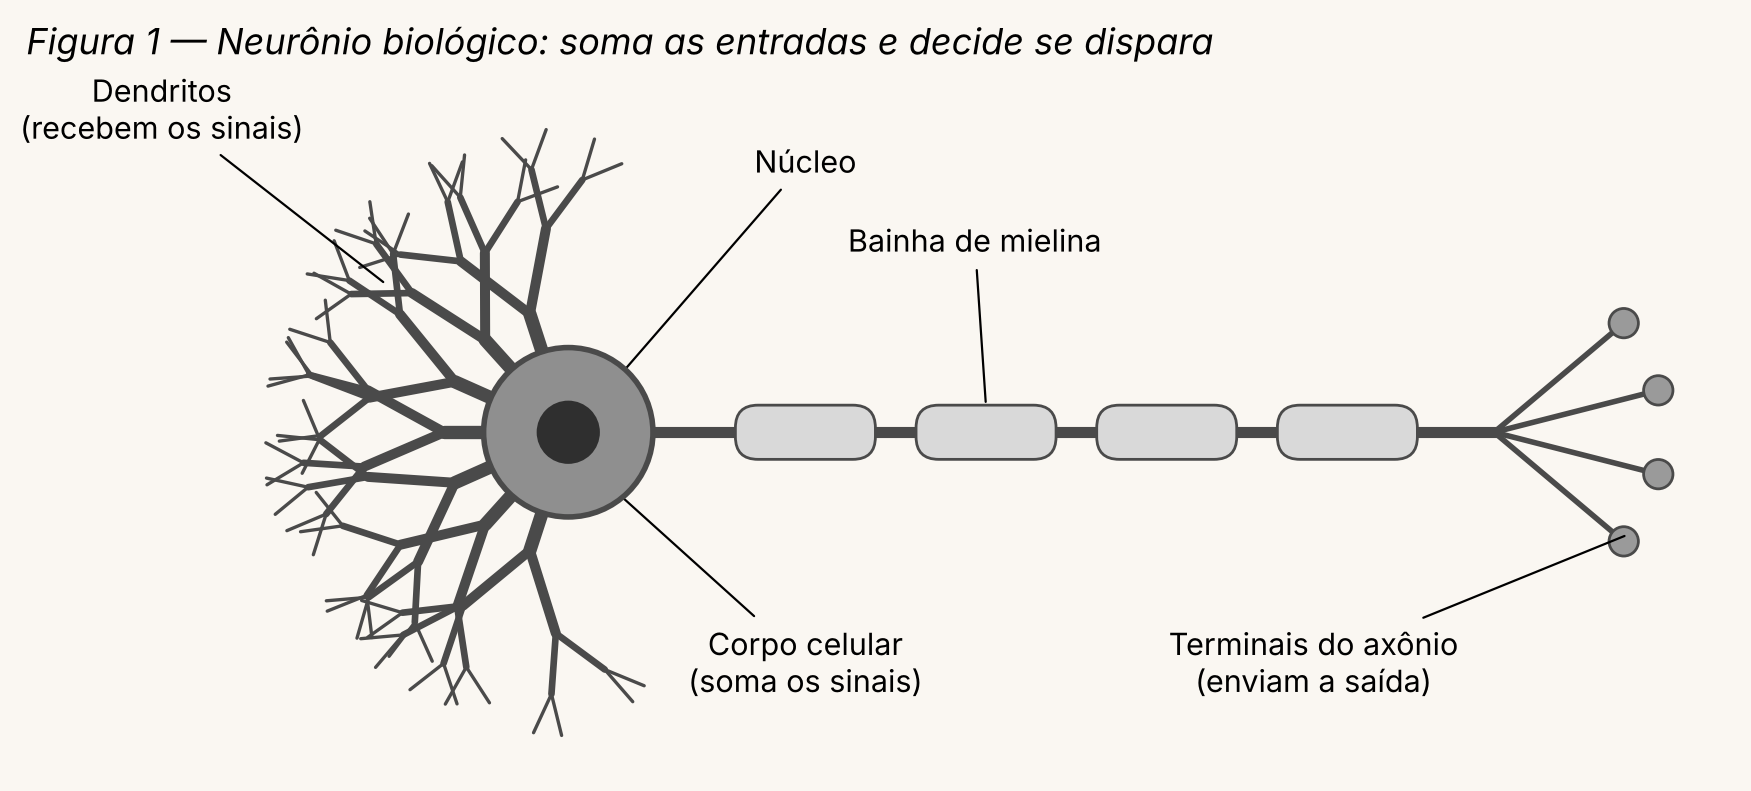

In [ ]:
desenhar_neuronio_biologico()

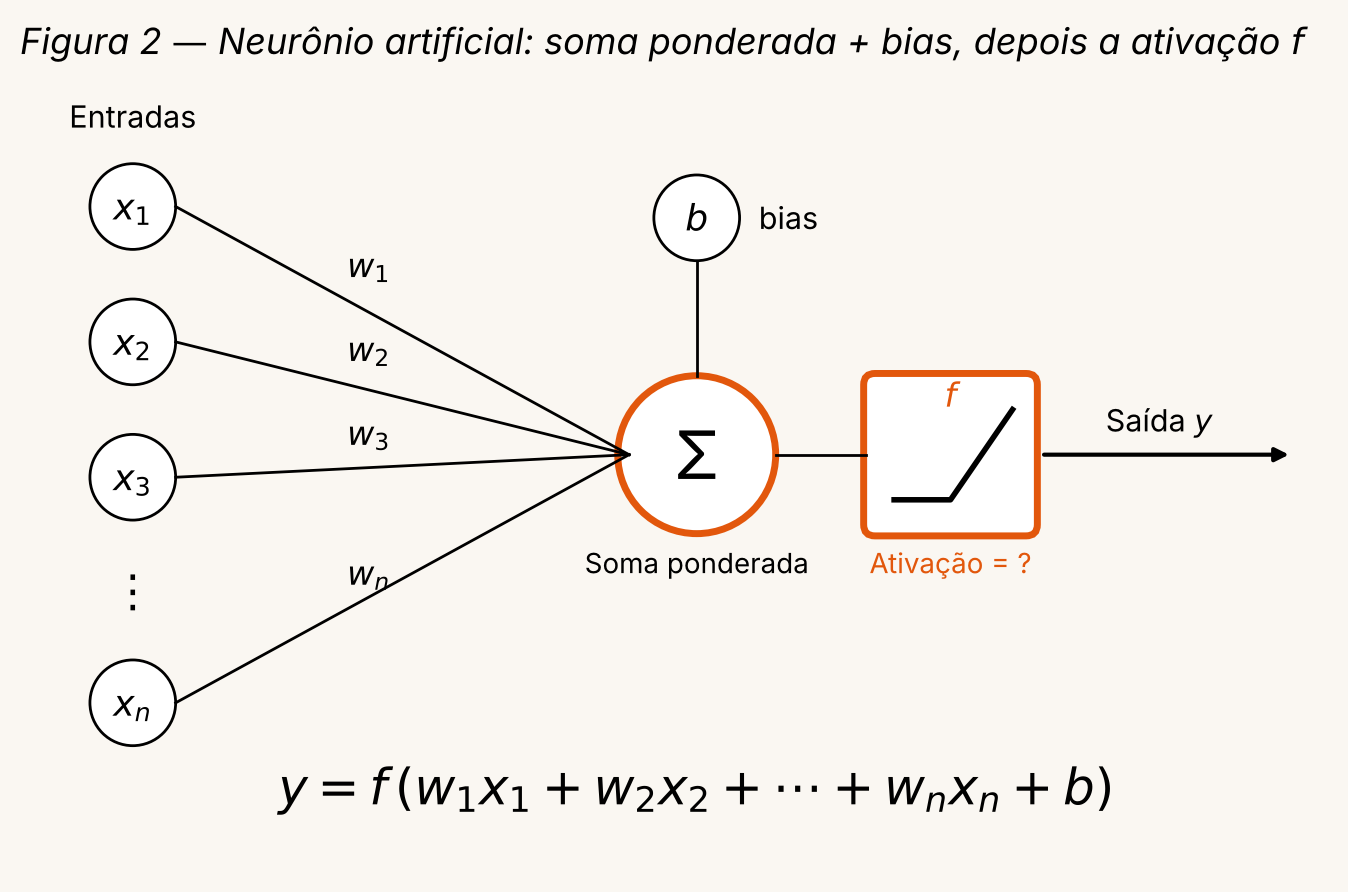

In [ ]:
desenhar_neuronio_artificial()

## 1.4 Observação

- **A analogia é só o ponto de partida.** O neurônio artificial é uma conta: multiplicar, somar e aplicar $f$. Não simula a biologia.
- **Sem o $f$, o neurônio é uma reta.** A soma ponderada $w_1x_1 + \cdots + w_nx_n + b$ é uma função linear. É a ativação que permite "dobrar" a reta — e é isso que as próximas fases vão medir.
- **O bias $b$ desloca o limiar.** Ele permite que o neurônio dispare mais cedo ou mais tarde, independentemente das entradas.
- **A semente fixa o desenho.** `np.random.default_rng(7)` faz os dendritos saírem sempre iguais. Troque o 7 por outro número e rode de novo: o neurônio muda de forma. O mesmo cuidado com sementes vai garantir, na Fase 2, que as quatro redes larguem dos mesmos pesos.
- **Para experimentar:** mude `nivel` de 4 para 5 na chamada de `desenhar_ramo` (mais ramificações) ou troque o desenho dentro da caixa $f$ por outra curva.

**Próxima fase:** criar os dados (dois anéis ruidosos) e montar a rede 2-16-16-1.

---
# Fase 2 — Os dados e a rede

## 2.1 Introdução

Para medir o efeito da função de ativação precisamos de três peças, e esta fase constrói as três.

**Os dados.** Dois anéis de pontos, um dentro do outro: o anel interno (raio 1) é a classe 0 e o externo (raio 2) é a classe 1, com um pouco de ruído. É um problema escolhido de propósito: **nenhuma reta separa** as duas classes. Para acertar, a rede precisa desenhar um círculo. São 800 pontos de treino e outros 800 de teste, que a rede nunca vê durante o treino.

**As ativações.** Quatro candidatas a $f$, cada uma com a sua derivada $f'$ (a inclinação da curva), que será usada pelo backprop na Fase 3:

| Ativação | $f(z)$ | $f'(z)$ |
|---|---|---|
| Sem ativação | $z$ | $1$ |
| Sigmoid | $\dfrac{1}{1+e^{-z}}$ | $f(z)\,(1-f(z))$ |
| tanh | $\tanh(z)$ | $1-\tanh^2(z)$ |
| ReLU | $\max(0, z)$ | $1$ se $z>0$, senão $0$ |

**A rede.** Uma MLP 2-16-16-1: 2 entradas ($x_1$ e $x_2$ de cada ponto), duas camadas ocultas com 16 neurônios cada e 1 neurônio de saída. Cada neurônio é exatamente o da Figura 2. A saída passa sempre por uma sigmoid, para virar uma probabilidade entre 0 e 1; o que muda entre os quatro experimentos é só o $f$ das camadas ocultas.

Nada é treinado ainda. O objetivo é deixar as peças prontas e conferir que as quatro redes **largam do mesmo ponto**.

## 2.2 Código

A célula abaixo define os dados, as ativações e a rede. Três pontos para reparar:

- `@` é a multiplicação de matrizes do NumPy. `x @ pesos[0]` calcula a soma ponderada de **todos** os 800 pontos e **todos** os 16 neurônios de uma vez.
- `criar_rede(semente=0)` devolve sempre os mesmos pesos. É isso que garante a comparação justa.
- `propagar` devolve também os valores intermediários (`z1`, `h1`, `z2`, `h2`), porque o backprop da Fase 3 vai precisar deles.

In [ ]:
# ---------- 1) OS DADOS: dois anéis ruidosos ----------
def criar_aneis(n, semente):
    """Cria n pontos em dois anéis: classe 0 no anel de raio 1, classe 1 no anel de raio 2."""
    rng = np.random.default_rng(semente)             # gerador de números aleatórios com semente
    classe = rng.integers(0, 2, n)                   # sorteia 0 ou 1 para cada ponto
    angulo = rng.uniform(0, 2 * np.pi, n)            # posição do ponto ao redor do círculo
    raio = 1 + classe + rng.normal(0, 0.25, n)       # raio 1 ou 2, mais um pouco de ruído
    x1 = raio * np.cos(angulo)                       # coordenada horizontal
    x2 = raio * np.sin(angulo)                       # coordenada vertical
    pontos = np.column_stack([x1, x2])               # tabela com n linhas e 2 colunas
    return pontos, classe


X, Y = criar_aneis(800, semente=0)      # dados de TREINO: a rede aprende com eles
Xt, Yt = criar_aneis(800, semente=1)    # dados de TESTE: a rede nunca vê durante o treino


# ---------- 2) AS QUATRO ATIVAÇÕES (f) E SUAS DERIVADAS (f') ----------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))                      # espreme qualquer número para entre 0 e 1


# Para cada nome: (a função f, a derivada f')
ATIVACOES = {
    "sem ativação": (lambda z: z,                 lambda z: np.ones_like(z)),
    "sigmoid":      (sigmoid,                     lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":         (np.tanh,                     lambda z: 1 - np.tanh(z) ** 2),
    "ReLU":         (lambda z: np.maximum(z, 0),  lambda z: (z > 0) * 1.0),
}
CORES = {"sem ativação": "#8c8577", "sigmoid": "#4a5bd6", "tanh": "#7b4fd1", "ReLU": "#e2570c"}


# ---------- 3) A REDE 2-16-16-1 ----------
CAMADAS = [2, 16, 16, 1]    # 2 entradas, duas camadas ocultas de 16 neurônios, 1 saída


def criar_rede(semente=0):
    """Cria os pesos (W) e bias (b) das três camadas. Mesma semente = mesma largada."""
    rng = np.random.default_rng(semente)
    pesos, bias = [], []
    for entradas, saidas in zip(CAMADAS[:-1], CAMADAS[1:]):          # pares (2,16), (16,16), (16,1)
        W = rng.normal(0, 1 / np.sqrt(entradas), (entradas, saidas))  # pesos pequenos e aleatórios
        pesos.append(W)
        bias.append(np.zeros(saidas))                                 # bias começa em zero
    return pesos, bias


def propagar(pesos, bias, f, x):
    """Passagem direta (forward): leva os dados da entrada até a saída da rede."""
    z1 = x @ pesos[0] + bias[0]          # camada 1: soma ponderada + bias
    h1 = f(z1)                           # camada 1: ativação
    z2 = h1 @ pesos[1] + bias[1]         # camada 2: soma ponderada + bias
    h2 = f(z2)                           # camada 2: ativação
    z3 = h2 @ pesos[2] + bias[2]         # camada de saída: soma ponderada + bias
    prob = sigmoid(z3).ravel()           # saída: probabilidade de o ponto ser da classe 1
    return z1, h1, z2, h2, prob


def acuracia(pesos, bias, f, x, y):
    """Fração de pontos que a rede classifica corretamente."""
    prob = propagar(pesos, bias, f, x)[-1]           # pega só a probabilidade final
    previsao = prob > 0.5                            # acima de 50% = classe 1
    return (previsao == y).mean()

## 2.3 Saída

Três saídas: os dados, as ativações e a rede antes do treino.

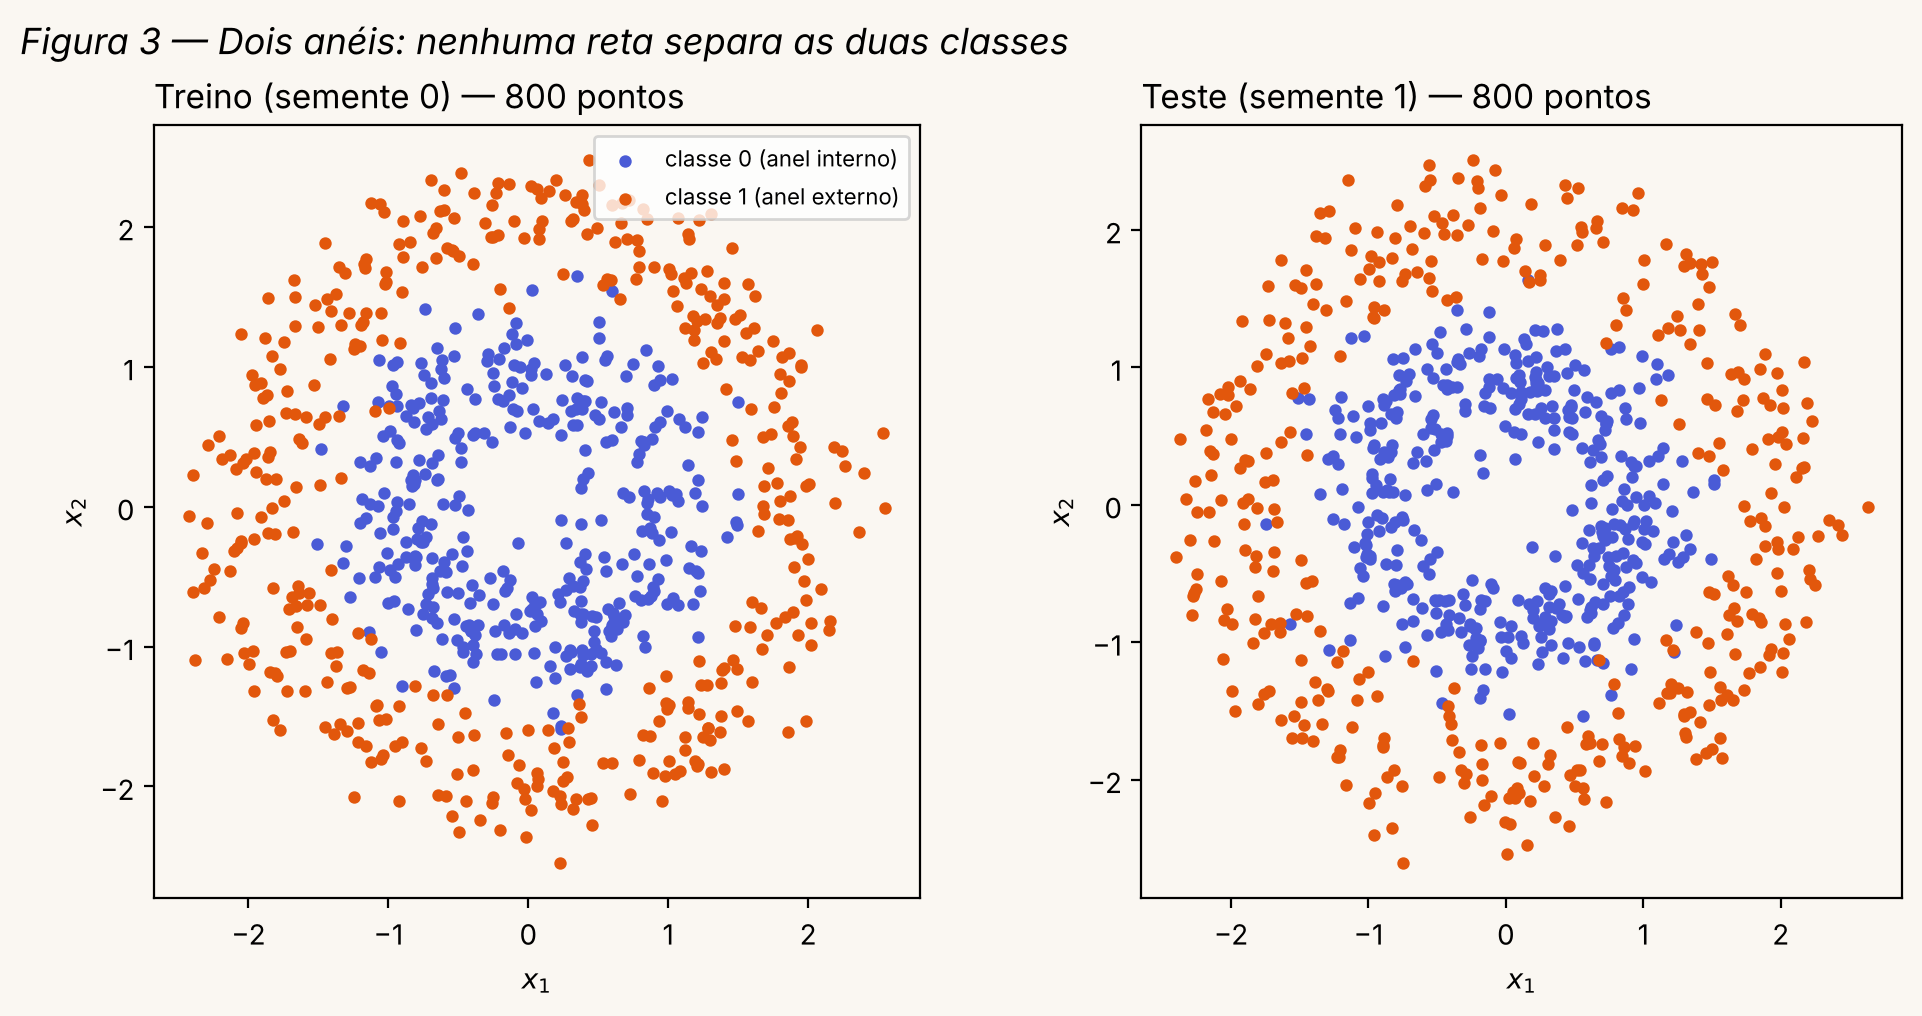

In [ ]:
# Figura 3 — os dados de treino e de teste
fig, eixos = plt.subplots(1, 2, figsize=(10, 5), facecolor=COR_FUNDO)
for ax, pontos, classe, titulo in [(eixos[0], X, Y, "Treino (semente 0)"), (eixos[1], Xt, Yt, "Teste (semente 1)")]:
    ax.scatter(pontos[classe == 0, 0], pontos[classe == 0, 1], s=12, color="#4a5bd6", label="classe 0 (anel interno)")
    ax.scatter(pontos[classe == 1, 0], pontos[classe == 1, 1], s=12, color="#e2570c", label="classe 1 (anel externo)")
    ax.set_title(f"{titulo} — {len(pontos)} pontos", loc="left")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_aspect("equal"); ax.set_facecolor(COR_FUNDO)
eixos[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Figura 3 — Dois anéis: nenhuma reta separa as duas classes", x=0.02, ha="left", fontsize=13, style="italic")
plt.tight_layout(); plt.show()

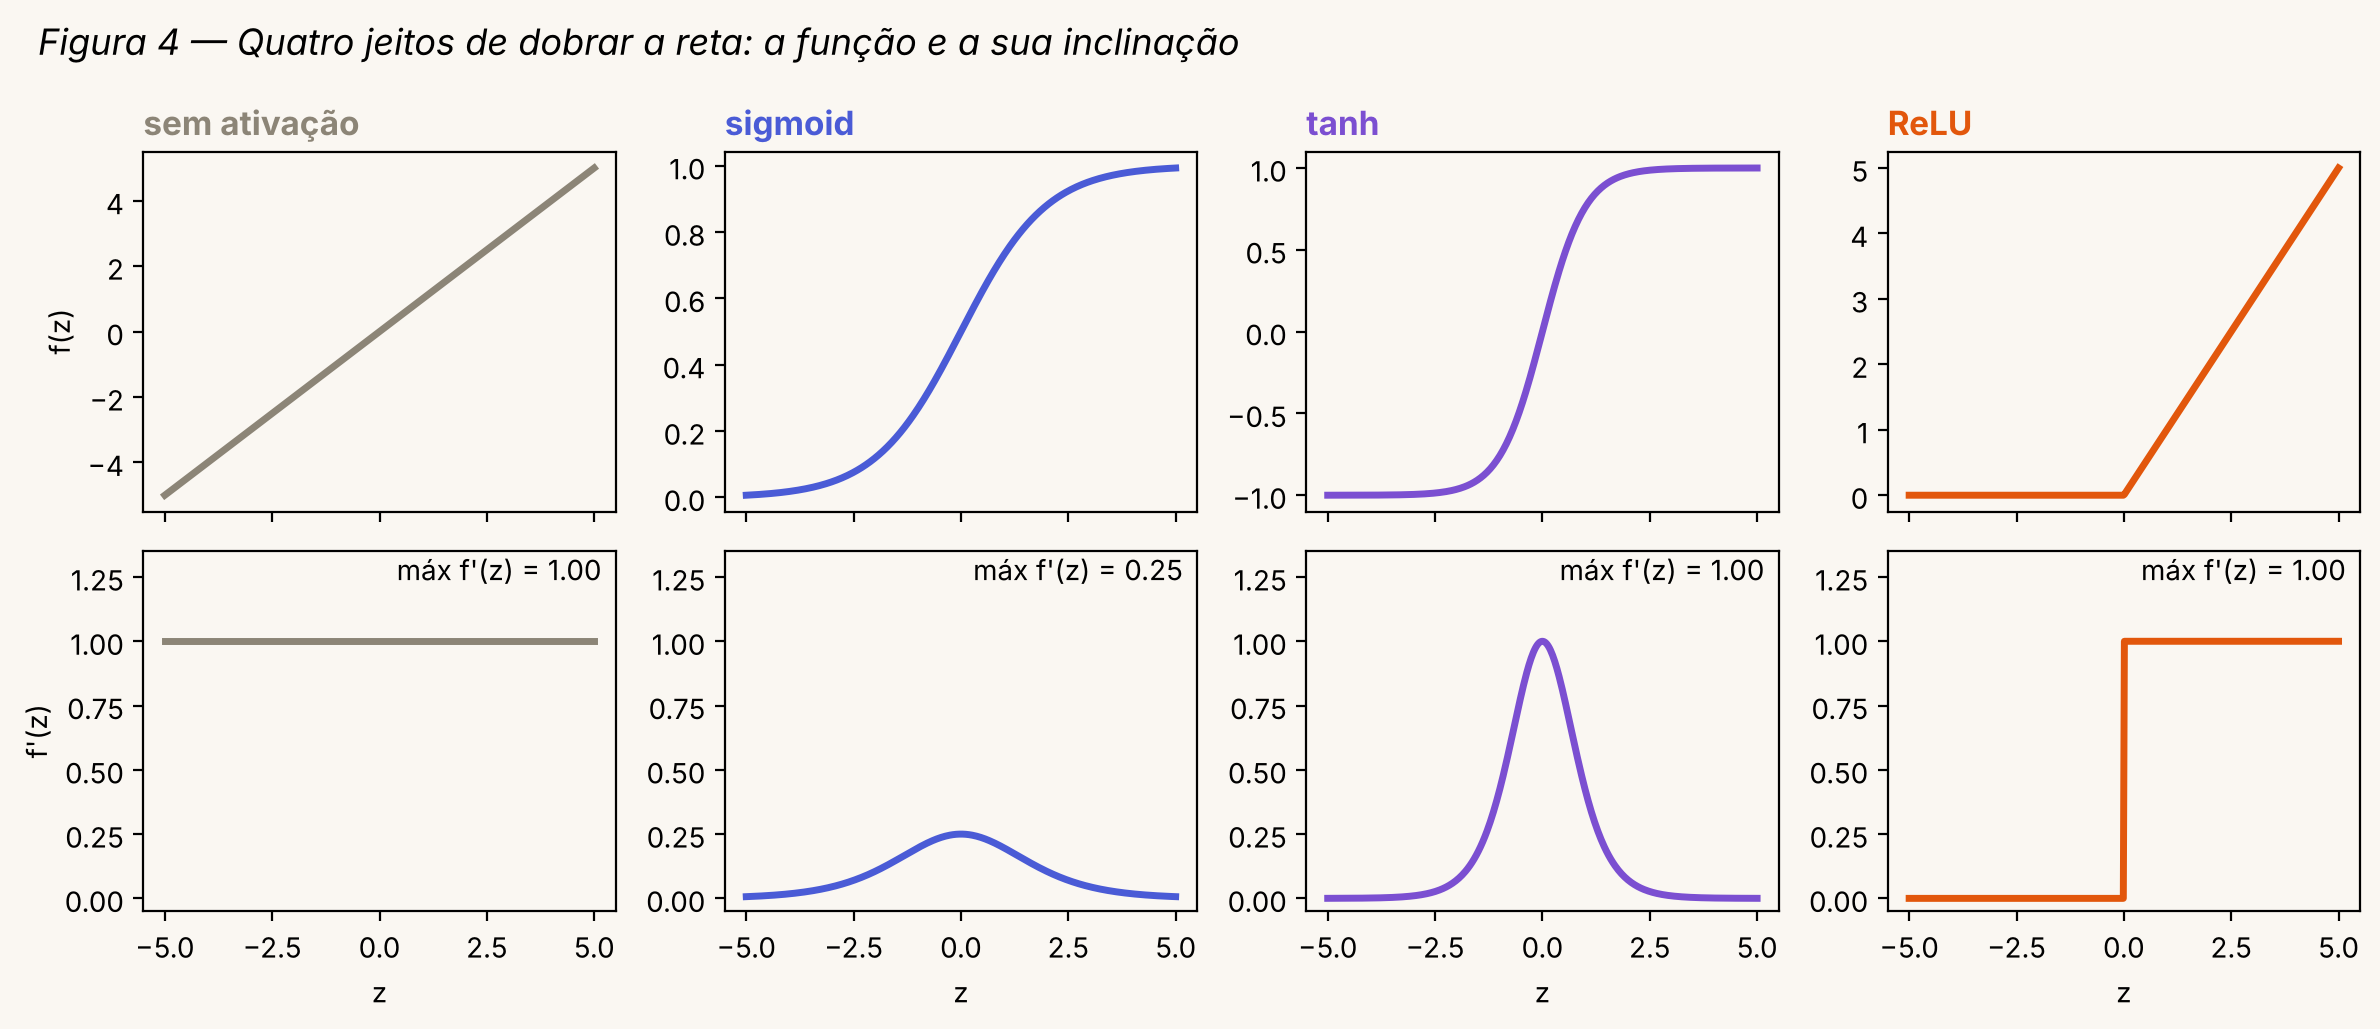

In [ ]:
# Figura 4 — as quatro ativações (em cima) e suas derivadas (embaixo)
z = np.linspace(-5, 5, 400)
fig, eixos = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True, facecolor=COR_FUNDO)
for coluna, nome in enumerate(ATIVACOES):
    f, df = ATIVACOES[nome]
    eixos[0, coluna].plot(z, f(z), color=CORES[nome], lw=2.5)
    eixos[0, coluna].set_title(nome, color=CORES[nome], fontweight="bold", loc="left")
    eixos[1, coluna].plot(z, df(z), color=CORES[nome], lw=2.5)
    eixos[1, coluna].set_ylim(-0.05, 1.35)
    eixos[1, coluna].text(0.97, 0.92, f"máx f'(z) = {df(z).max():.2f}", transform=eixos[1, coluna].transAxes, ha="right")
    eixos[1, coluna].set_xlabel("z")
    eixos[0, coluna].set_facecolor(COR_FUNDO); eixos[1, coluna].set_facecolor(COR_FUNDO)
eixos[0, 0].set_ylabel("f(z)"); eixos[1, 0].set_ylabel("f'(z)")
fig.suptitle("Figura 4 — Quatro jeitos de dobrar a reta: a função e a sua inclinação", x=0.02, ha="left", fontsize=13, style="italic")
plt.tight_layout(); plt.show()

In [ ]:
# A rede recém-criada: tamanho de cada camada e total de parâmetros
pesos, bias = criar_rede(semente=0)
total = 0
for numero, (W, b) in enumerate(zip(pesos, bias), start=1):
    print(f"Camada {numero}: pesos {W.shape}, bias {b.shape} -> {W.size + b.size} parâmetros")
    total += W.size + b.size
print(f"Total de parâmetros da rede: {total}\n")

# Acurácia ANTES do treino: mesma largada para as quatro ativações
print("Acurácia no teste antes de treinar (pesos aleatórios):")
for nome, (f, df) in ATIVACOES.items():
    pesos, bias = criar_rede(semente=0)              # todas partem dos mesmos pesos
    print(f"  {nome:13s} {acuracia(pesos, bias, f, Xt, Yt):.1%}")

Camada 1: pesos (2, 16), bias (16,) -> 48 parâmetros
Camada 2: pesos (16, 16), bias (16,) -> 272 parâmetros
Camada 3: pesos (16, 1), bias (1,) -> 17 parâmetros
Total de parâmetros da rede: 337

Acurácia no teste antes de treinar (pesos aleatórios):
  sem ativação  51.6%
  sigmoid       51.5%
  tanh          51.4%
  ReLU          49.8%


## 2.4 Observação

- **O problema não é linear.** Na Figura 3 a classe 0 está cercada pela classe 1. Uma reta sempre deixa pontos das duas classes do mesmo lado; por isso a rede "sem ativação" está condenada desde já.
- **A inclinação da sigmoid nunca passa de 0,25.** Na Figura 4, tanh e ReLU chegam a inclinação 1; a sigmoid fica em um quarto disso. O backprop multiplica por $f'$ uma vez por camada, então esse 0,25 vai encolher o gradiente duas vezes. Guarde esse número: ele explica a Fase 3.
- **A rede tem 337 parâmetros.** São 48 na camada 1 (2×16 pesos + 16 bias), 272 na camada 2 (16×16 + 16) e 17 na saída (16 + 1).
- **Antes do treino, ninguém sabe nada.** As acurácias iniciais ficam perto de 50%, o equivalente a jogar uma moeda. Os pesos são idênticos nas quatro redes; as pequenas diferenças vêm só de como cada $f$ transforma esses mesmos pesos.
- **Treino e teste usam sementes diferentes** (0 e 1): mesmos anéis, pontos diferentes. Medir no teste mostra se a rede aprendeu o formato do problema, e não se decorou os pontos.
- **Para experimentar:** troque o ruído de `0.25` para `0.5` em `criar_aneis` e veja os anéis se misturarem; ou troque `CAMADAS` para `[2, 4, 4, 1]` e confira o novo total de parâmetros.

**Próxima fase:** o backprop à mão e o treino das quatro redes por 600 passos.

---
# Fase 3 — Backprop à mão e o treino das quatro redes

## 3.1 Introdução

Até aqui a rede só chuta. Treinar é repetir quatro movimentos, 600 vezes:

1. **Ida (forward).** A rede recebe os 800 pontos de treino e devolve uma probabilidade para cada um.
2. **Erro.** Comparamos a probabilidade com a resposta certa: $\delta_3 = p - y$. Se a rede disse 0,9 e a resposta era 1, o erro é pequeno; se disse 0,9 e era 0, é grande.
3. **Volta (backpropagation).** O erro caminha da saída para a entrada. Em cada camada ele é multiplicado pelos pesos e pela **derivada da ativação** $f'$:

$$\delta_2 = (\delta_3 W_3^T)\cdot f'(z_2) \qquad \delta_1 = (\delta_2 W_2^T)\cdot f'(z_1)$$

4. **Correção.** Cada peso anda um pouco na direção que reduz o erro: $W \leftarrow W - \text{taxa} \times \text{gradiente}$.

O ponto central do notebook está no movimento 3: para chegar à camada 1, o erro é multiplicado por $f'$ **duas vezes**.

$$\frac{\partial L}{\partial W_1} \propto f'(z_2)\, W_2\, f'(z_1)$$

Com tanh e ReLU, $f'$ chega a 1 e o erro passa quase inteiro. Com a sigmoid, $f'$ é no máximo 0,25 (Figura 4): duas multiplicações deixam no máximo $0{,}25 \times 0{,}25 \approx 6\%$ do sinal. A primeira camada mal fica sabendo que errou.

Tudo aqui é feito à mão em NumPy, sem TensorFlow nem PyTorch. É exatamente a conta que essas bibliotecas fazem por baixo.

## 3.2 Código

Duas funções. `treinar_um_passo` faz os quatro movimentos uma vez; `treinar_rede` repete isso 600 vezes e anota o histórico.

- `[:, None]` transforma a lista de 800 erros numa coluna (800 linhas × 1 coluna), para as multiplicações de matriz encaixarem.
- `.T` é a transposta: inverte linhas e colunas. É o que faz o erro andar "para trás" pelos mesmos pesos da ida.
- A rede **aprende** com `X, Y` (treino) e é **medida** com `Xt, Yt` (teste).
- `np.linalg.norm` resume uma matriz inteira de gradientes em um único número: o seu tamanho.

In [ ]:
PASSOS = 600    # quantas vezes a rede corrige os pesos
TAXA = 0.5      # taxa de aprendizado: o tamanho de cada correção


def treinar_um_passo(pesos, bias, nome, x, y):
    """Um passo de treino: propaga, calcula o erro, volta corrigindo os pesos (backprop)."""
    f, df = ATIVACOES[nome]                          # a ativação escolhida e a sua derivada

    # 1) IDA: a rede faz a previsão
    z1, h1, z2, h2, prob = propagar(pesos, bias, f, x)

    # 2) VOLTA: o erro caminha da saída para a entrada (regra da cadeia)
    d3 = (prob - y)[:, None] / len(y)                # erro na saída: previsão menos resposta certa
    d2 = (d3 @ pesos[2].T) * df(z2)                  # erro na camada 2: multiplica por f' (1ª vez)
    d1 = (d2 @ pesos[1].T) * df(z1)                  # erro na camada 1: multiplica por f' (2ª vez)

    # 3) GRADIENTES: quanto cada peso contribuiu para o erro
    grad_W1 = x.T @ d1                               # gradiente dos pesos da camada 1
    grad_W2 = h1.T @ d2                              # gradiente dos pesos da camada 2
    grad_W3 = h2.T @ d3                              # gradiente dos pesos da saída

    # 4) CORREÇÃO: cada peso anda um pouco na direção que diminui o erro
    pesos[0] -= TAXA * grad_W1;  bias[0] -= TAXA * d1.sum(axis=0)
    pesos[1] -= TAXA * grad_W2;  bias[1] -= TAXA * d2.sum(axis=0)
    pesos[2] -= TAXA * grad_W3;  bias[2] -= TAXA * d3.sum(axis=0)

    return np.linalg.norm(grad_W1)                   # "tamanho" do gradiente que chegou à camada 1


def treinar_rede(nome):
    """Treina uma rede do zero com a ativação escolhida e guarda o histórico."""
    f, df = ATIVACOES[nome]
    pesos, bias = criar_rede(semente=0)              # mesma largada para as quatro
    historico_acuracia = []                          # acurácia no teste a cada passo
    historico_gradiente = []                         # gradiente da camada 1 a cada passo
    for passo in range(PASSOS):
        gradiente = treinar_um_passo(pesos, bias, nome, X, Y)       # aprende com o TREINO
        historico_gradiente.append(gradiente)
        historico_acuracia.append(acuracia(pesos, bias, f, Xt, Yt)) # mede no TESTE
    return pesos, bias, historico_acuracia, historico_gradiente

## 3.3 Saída

Primeiro treinamos as quatro redes e olhamos o diário de bordo. Depois, o gradiente da camada 1 no primeiro passo.

In [ ]:
# Treina as quatro redes e guarda tudo em dicionários (a Fase 4 vai usar)
redes, hist_acuracia, hist_gradiente = {}, {}, {}
for nome in ATIVACOES:
    pesos, bias, hist_acuracia[nome], hist_gradiente[nome] = treinar_rede(nome)
    redes[nome] = (pesos, bias)

# Diário de bordo: acurácia no teste em alguns passos do treino
marcos = [1, 10, 30, 60, 100, 200, 400, 600]
print("Acurácia no teste ao longo do treino\n")
print(f"{'passo':>13s}" + "".join(f"{m:>8d}" for m in marcos))
for nome in ATIVACOES:
    print(f"{nome:>13s}" + "".join(f"{hist_acuracia[nome][m - 1]:>8.1%}" for m in marcos))

Acurácia no teste ao longo do treino

        passo       1      10      30      60     100     200     400     600
 sem ativação   47.9%   35.6%   35.6%   35.6%   35.6%   35.6%   35.6%   35.6%
      sigmoid   58.0%   48.5%   48.5%   48.5%   48.5%   39.4%   47.9%   64.5%
         tanh   53.8%   66.6%   79.2%   96.2%   96.1%   96.4%   96.4%   96.4%
         ReLU   48.5%   61.9%   95.0%   96.6%   96.6%   96.5%   96.0%   96.1%


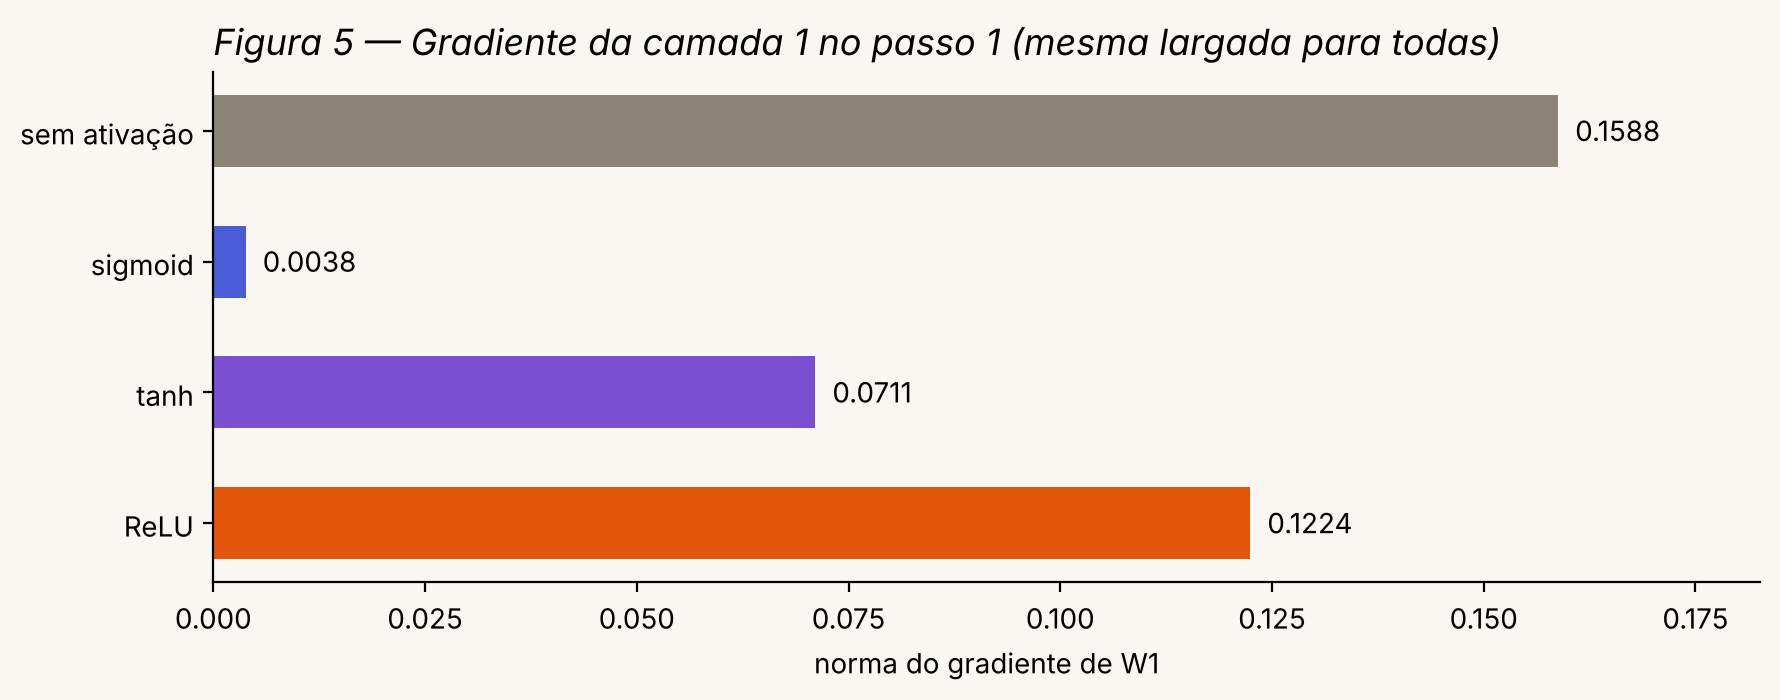

Sigmoid: 32x menor que ReLU e 19x menor que tanh


In [ ]:
# Figura 5 — o gradiente que chega à camada 1 logo no primeiro passo
nomes = list(ATIVACOES)[::-1]                        # invertido: o barh desenha de baixo para cima
valores = [hist_gradiente[nome][0] for nome in nomes]

fig, ax = plt.subplots(figsize=(9, 3.6), facecolor=COR_FUNDO)
ax.barh(nomes, valores, color=[CORES[nome] for nome in nomes], height=0.55)
for posicao, valor in enumerate(valores):
    ax.text(valor + 0.002, posicao, f"{valor:.4f}", va="center")
ax.set_xlim(0, max(valores) * 1.15)
ax.set_xlabel("norma do gradiente de W1")
ax.set_facecolor(COR_FUNDO); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Figura 5 — Gradiente da camada 1 no passo 1 (mesma largada para todas)", loc="left", fontsize=13, style="italic")
plt.tight_layout(); plt.show()

g = {nome: hist_gradiente[nome][0] for nome in ATIVACOES}
print(f"Sigmoid: {g['ReLU'] / g['sigmoid']:.0f}x menor que ReLU e {g['tanh'] / g['sigmoid']:.0f}x menor que tanh")

## 3.4 Observação

- **Mesma largada, destinos diferentes.** As quatro redes partem dos mesmos pesos e veem os mesmos dados. Depois de 600 passos: sem ativação 35,6%, sigmoid 64,5%, tanh 96,4% e ReLU 96,1%.
- **tanh e ReLU resolvem em menos de 60 passos.** No diário de bordo, as duas já passam de 96% no passo 60 e ficam lá.
- **A sigmoid aprende devagar, e a Figura 5 mostra o motivo.** No passo 1 o gradiente que chega à camada 1 é 0,0038, contra 0,1224 da ReLU (32 vezes menor) e 0,0711 da tanh (19 vezes menor). É o efeito do $f' \le 0{,}25$ multiplicado duas vezes. Esse fenômeno tem nome: **desvanecimento do gradiente** (*vanishing gradient*).
- **A sigmoid piora antes de melhorar.** No passo 200 ela está abaixo de 50%, pior que uma moeda, e só então começa a subir. Ela não é incapaz, é lenta: rodando 1000 passos em vez de 600, chega a 95,9%.
- **Sem ativação o gradiente é o maior de todos (0,1588) e não adianta nada.** O sinal chega forte, mas a rede só sabe desenhar uma reta. Gradiente grande não compensa falta de capacidade. Os 35,6% ficam até abaixo dos 50% de uma moeda neste conjunto de teste.
- **Para experimentar:** mude `PASSOS` para 1000 e veja a sigmoid alcançar as outras; ou mude `TAXA` para 0.05 e para 2.0 e compare a velocidade.

**Próxima fase:** ver os resultados — as fronteiras de decisão e as curvas de acurácia.

---
# Fase 4 — Resultados: o que cada rede aprendeu

## 4.1 Introdução

A Fase 3 deixou quatro redes treinadas e uma tabela de números. Falta **ver** o que cada uma aprendeu. Duas figuras fazem isso.

**A fronteira de decisão.** Pedimos à rede uma previsão para cada ponto de uma grade que cobre o plano inteiro (300 × 300 = 90.000 pontos) e pintamos o resultado: azul onde ela aposta na classe 0, vermelho onde aposta na classe 1. A linha preta marca onde a probabilidade é exatamente 50%: é a fronteira. Para acertar os dois anéis, essa linha precisa ser um círculo entre eles.

**A curva de acurácia.** O histórico guardado na Fase 3, passo a passo. Mostra não só aonde cada rede chegou, mas **em que velocidade**.

No fim, um quadro-resumo e a regra prática: qual ativação usar e onde.

## 4.2 Código

Duas funções de desenho, que usam o que ficou guardado na Fase 3: `redes` (os pesos treinados) e `hist_acuracia` (o histórico).

- `np.meshgrid` cria a grade de pontos; `.ravel()` desmancha a grade numa lista para passar pela rede; `.reshape` monta de volta o formato de imagem.
- `ax.imshow` pinta o fundo com as probabilidades; `ax.contour(..., levels=[0.5])` traça só a linha dos 50%.
- Reaproveitamos `propagar` da Fase 2: prever é só fazer a ida, sem a volta.

In [ ]:
def desenhar_fronteiras():
    """Figura 6: o que cada rede aprendeu, pintando o plano inteiro."""
    limite = 3.6
    # Malha: uma grade de 300 x 300 pontos cobrindo todo o plano
    gx, gy = np.meshgrid(np.linspace(-limite, limite, 300), np.linspace(-limite, limite, 300))
    malha = np.column_stack([gx.ravel(), gy.ravel()])            # 90.000 pontos (x1, x2)

    fig, eixos = plt.subplots(2, 2, figsize=(9, 9.4), facecolor=COR_FUNDO)
    for ax, nome in zip(eixos.ravel(), ATIVACOES):
        pesos, bias = redes[nome]                                # a rede treinada na Fase 3
        f = ATIVACOES[nome][0]
        prob = propagar(pesos, bias, f, malha)[-1].reshape(gx.shape)   # previsão em cada ponto da grade
        ax.imshow(prob, extent=(-limite, limite, -limite, limite), origin="lower",
                  cmap="coolwarm", vmin=0, vmax=1, alpha=0.5)    # fundo: azul = classe 0, vermelho = classe 1
        ax.contour(gx, gy, prob, levels=[0.5], colors="black", linewidths=1.8)   # a fronteira: prob = 50%
        ax.scatter(Xt[:300, 0], Xt[:300, 1], c=Yt[:300], cmap="coolwarm", s=14,
                   edgecolors="white", linewidths=0.4)           # 300 pontos de teste por cima
        ax.set_title(f"{nome} — teste {hist_acuracia[nome][-1]:.1%}", color=CORES[nome],
                     fontweight="bold", loc="left")
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Figura 6 — Mesma rede, só f muda: a fronteira após {PASSOS} passos",
                 x=0.02, ha="left", fontsize=13, style="italic")
    plt.tight_layout(); plt.show()


def desenhar_curvas():
    """Figura 7: a acurácia no teste a cada passo do treino."""
    fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=COR_FUNDO)
    ajuste = {"tanh": 0.025, "ReLU": -0.025}                     # afasta dois rótulos que ficariam sobrepostos
    for nome in ATIVACOES:
        ax.plot(range(1, PASSOS + 1), hist_acuracia[nome], color=CORES[nome], lw=2)
        final = hist_acuracia[nome][-1]
        ax.text(PASSOS + 6, final + ajuste.get(nome, 0), f"{nome} {final:.1%}", color=CORES[nome], va="center")
    ax.axhline(0.5, color="gray", lw=0.8, ls=":")                # linha da moeda: 50%
    ax.set_xlim(0, PASSOS * 1.2); ax.set_ylim(0.25, 1.02)
    ax.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0%}")
    ax.set_xlabel("passo de treino"); ax.set_ylabel("acurácia no teste")
    ax.set_facecolor(COR_FUNDO); ax.spines[["top", "right"]].set_visible(False)
    ax.set_title("Figura 7 — Acurácia em 800 pontos nunca vistos, ao longo do treino",
                 loc="left", fontsize=13, style="italic")
    plt.tight_layout(); plt.show()

## 4.3 Saída

As fronteiras, as curvas e o quadro final.

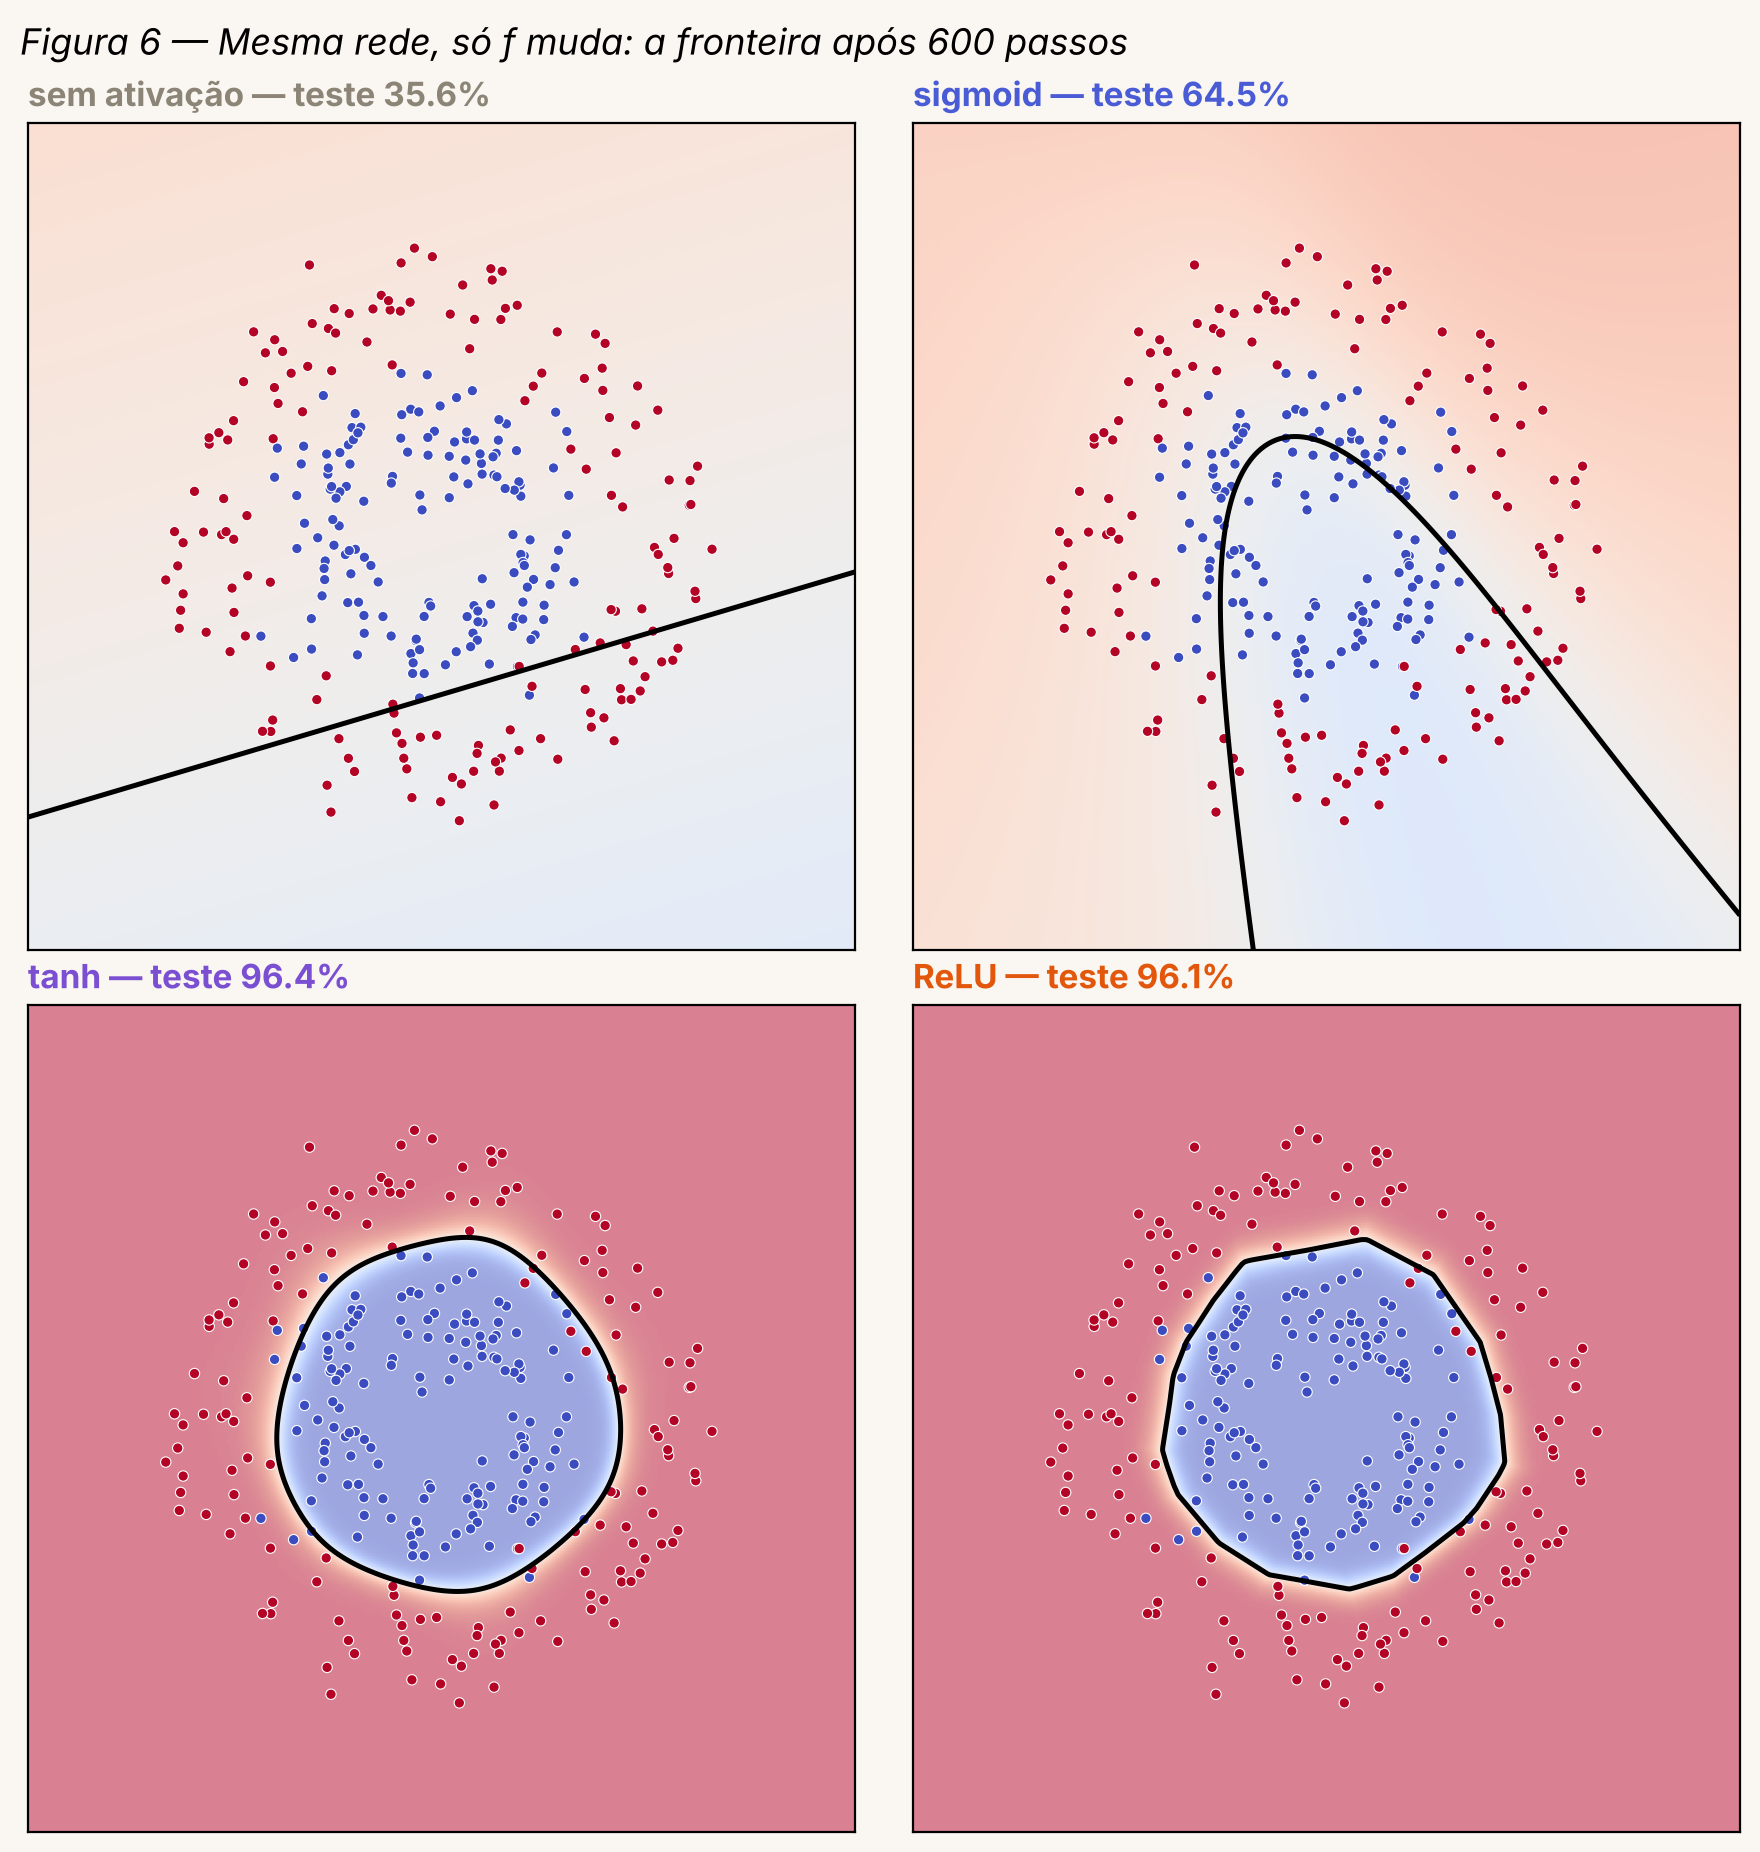

In [ ]:
desenhar_fronteiras()

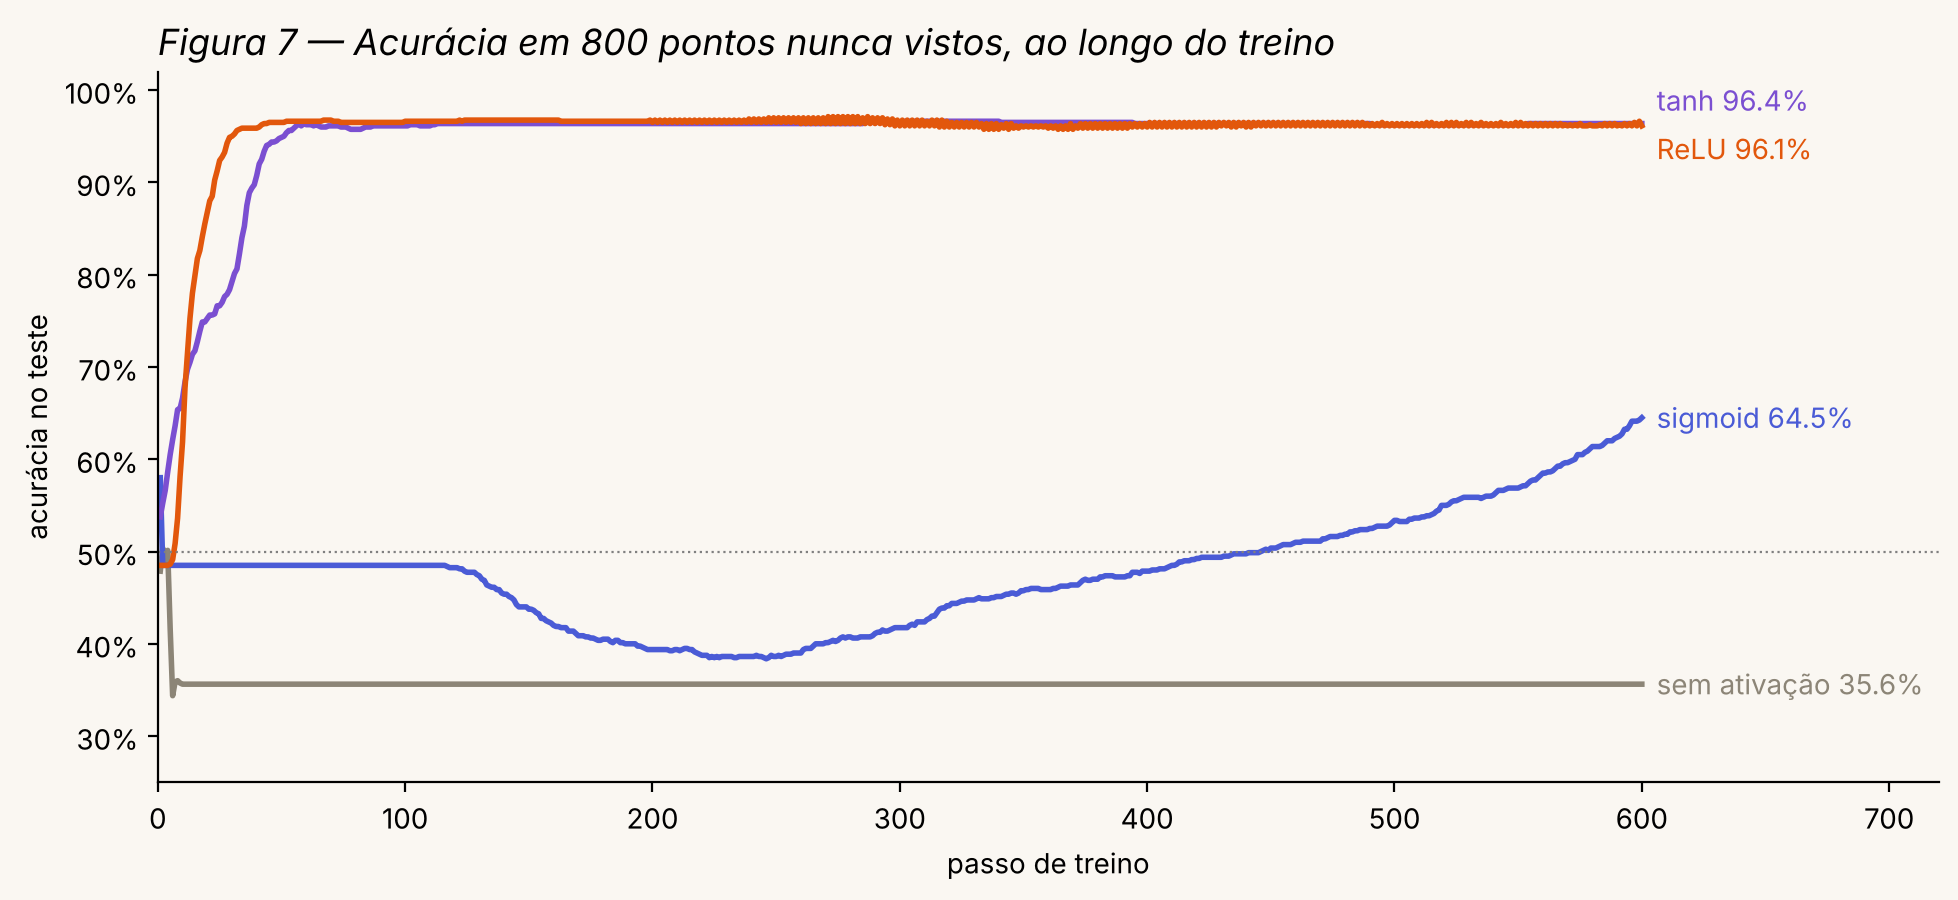

In [ ]:
desenhar_curvas()

In [ ]:
# Quadro final: acurácia, passo em que cada rede cruza 90% e unidades ReLU mortas
print(f"{'ativação':>13s} {'acurácia final':>15s} {'cruza 90% no passo':>20s}")
for nome in ATIVACOES:
    passos_acima = [p + 1 for p, a in enumerate(hist_acuracia[nome]) if a >= 0.90]
    cruzou = str(passos_acima[0]) if passos_acima else "não cruzou"
    print(f"{nome:>13s} {hist_acuracia[nome][-1]:>15.1%} {cruzou:>20s}")

# Unidade "morta": neurônio ReLU que devolve zero para TODOS os pontos de treino
pesos, bias = redes["ReLU"]
z1, h1, z2, h2, prob = propagar(pesos, bias, ATIVACOES["ReLU"][0], X)
mortas = (h1.sum(axis=0) == 0).sum() + (h2.sum(axis=0) == 0).sum()
print(f"\nUnidades ReLU mortas: {mortas} de 32")

     ativação  acurácia final   cruza 90% no passo
 sem ativação           35.6%           não cruzou
      sigmoid           64.5%           não cruzou
         tanh           96.4%                   40
         ReLU           96.1%                   23

Unidades ReLU mortas: 0 de 32


## 4.4 Observação

- **Sem ativação, a fronteira é uma reta.** Empilhar camadas lineares não adianta: $W_2(W_1x + b_1) + b_2 = (W_2W_1)\,x + (W_2b_1 + b_2)$, que é outra função linear. Três camadas sem $f$ valem uma só.
- **A sigmoid está no meio do caminho.** A fronteira já entortou, mas ainda não fechou o círculo. Faltou tempo, não capacidade (Fase 3: com 1000 passos ela chega a 95,9%).
- **tanh e ReLU fecham o círculo, cada uma do seu jeito.** A fronteira da tanh é arredondada; a da ReLU é feita de pequenos trechos retos, porque a ReLU é ela mesma feita de dois pedaços de reta.
- **Nenhuma unidade ReLU morreu** (0 de 32). O risco da ReLU é um neurônio ficar preso no lado zero e parar de aprender; aqui não aconteceu.
- **Os 96% são o teto do problema.** Os anéis têm ruído e se encostam; alguns pontos estão do lado "errado" e nenhuma fronteira razoável os acerta.

**Regra prática**

| Ativação | Onde usar | Por quê |
|---|---|---|
| Sem ativação | Nunca nas camadas ocultas | A rede inteira vira uma reta |
| Sigmoid | Só na saída | Transforma um número em probabilidade (0 a 1); nas camadas ocultas, encolhe o gradiente |
| tanh | Camadas ocultas, boa opção | Centrada em zero, inclinação até 1; comum em redes recorrentes |
| ReLU | Camadas ocultas, escolha padrão | Barata de calcular, inclinação 1 para $z > 0$; ficar de olho em unidades mortas |

**Para experimentar:** troque o `cmap` das figuras; aumente o ruído dos anéis na Fase 2 e rode tudo de novo; ou acrescente uma quinta ativação ao dicionário `ATIVACOES` (por exemplo a *Leaky ReLU*: `lambda z: np.where(z > 0, z, 0.01 * z)`, com derivada `lambda z: np.where(z > 0, 1.0, 0.01)`) e uma cor para ela em `CORES`.

---
# Conclusão

Uma rede, quatro ativações, 600 passos. A única linha que mudou foi o $f$.

| Ativação | Acurácia no teste | Gradiente da camada 1 no passo 1 |
|---|---|---|
| Sem ativação | 35,6% | 0,1588 |
| Sigmoid | 64,5% | 0,0038 |
| tanh | 96,4% | 0,0711 |
| ReLU | 96,1% | 0,1224 |

A função de ativação faz duas coisas. **Dá à rede a capacidade de dobrar a reta**: sem ela, qualquer número de camadas vale uma só. E **decide quanto do erro chega às primeiras camadas**: a cada camada o gradiente é multiplicado por $f'$, e uma derivada pequena, como a da sigmoid, faz a rede aprender devagar.

*Experimento original: post de @neuron.machinelearning. Código e figuras deste notebook: implementação própria.*